# 03 · Estado enriquecido, mercados extra y serie real

Tres pruebas para ir más allá de los mínimos, con **Q-Learning y SARSA**, resultados ejecutados y controles comunes:

1. **Estado enriquecido:** comprobar si añadir distancia a una media larga y volatilidad mejora los mercados de reversión y regímenes, donde el estado del taller puede quedarse corto.
2. **Mercados extra:** una tendencia persistente y una difusión con saltos. Buscamos distinguir una señal aprendible de un riesgo que los indicadores no pueden anticipar.
3. **Serie real:** cierres diarios del S&P 500, separando entrenamiento (2017–2021), validación (2022–2023) y test (2024–2025).

La pregunta no es «¿sale una curva bonita?», sino **qué mejora al cambiar el estado y qué generaliza a datos no vistos**. Se mantienen las acciones, la comisión del 0,1 %, la recompensa y la contabilidad del taller. El código nuevo está en `src/extras.py`; `SimpleTradingEnv` y los cuatro generadores originales no cambian.

**Salidas:** `results/03_extras.csv` (esquema común para el 04), resultados por semilla y episodio, deltas emparejados, bloques reales, conclusiones y figuras `03_*.png`.

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src" / "extras.py").exists():
    raise RuntimeError("Ejecuta este notebook desde la raíz del repositorio o desde notebooks/")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.env import SimpleTradingEnv
from src.agents import BuyHoldAgent
from src.experiment import RESULT_COLUMNS, RESULTS_DIR, save_results
from src.style import setup, savefig, AGENT_COLORS
from src.extras import (
    SYNTHETIC_MARKETS, LABELS, ALGORITHMS, FeatureTradingEnv, CashAgent,
    prepare, causal_features, fit_encoder, calibration_series, evaluation_series,
    real_data, real_indices, run_training, run_test, baselines, paired_state_effect,
    load_model, run_extra_episode, real_blocks, code_fingerprint,
)
from src.markets import make_prices

setup()
pd.set_option("display.precision", 4)
QUICK = os.environ.get("NB_QUICK") == "1"
RECALCULAR = False
N_JOBS = min(6, max(1, (os.cpu_count() or 2) // 2))
SEEDS = [0] if QUICK else [0, 1, 2, 3, 4]
N_EP = 25 if QUICK else 800
N_STEPS = 160 if QUICK else 500
N_VAL = 5 if QUICK else 100
N_TEST = 8 if QUICK else 200
SUF = "_quick" if QUICK else ""
MARKETS_03 = [*SYNTHETIC_MARKETS, "sp500_real"]
BASE = dict(alpha=0.001, gamma=0.9, epsilon_decay=0.99, epsilon_min=0.01,
            n_episodes=N_EP, n_steps=N_STEPS, n_val=N_VAL, n_test=N_TEST, real_window=252)
def figure(fig, name):
    return savefig(fig, name + SUF)

print(f"{'PRUEBA RÁPIDA' if QUICK else 'EXPERIMENTO COMPLETO'} · {len(SEEDS)} semillas · {N_EP} episodios"
      f" · {N_JOBS} procesos · {N_TEST} series sintéticas de test")
print("La serie real tiene un único recorrido de test; las semillas son entrenamientos, no historias independientes.")

EXPERIMENTO COMPLETO · 5 semillas · 800 episodios · 6 procesos · 200 series sintéticas de test
La serie real tiene un único recorrido de test; las semillas son entrenamientos, no historias independientes.


## 1. Protocolo: comparación controlada y sin mirar al futuro

| Elemento | Decisión |
|---|---|
| Algoritmos | Q-Learning y SARSA del módulo común; se conserva su orden de actualización |
| Estado base | Tendencia del taller (10 bins) × posición: **20 estados** |
| Estado enriquecido | Tendencia (10) × distancia MA30 (3) × volatilidad20 (3) × posición: **180 estados** si los cuantiles son distintos |
| Hiperparámetros | α=0,001; γ=0,9; ε inicial=1, decaimiento=0,99, mínimo=0,01; 800 episodios en ambos estados |
| Sintéticos | 500 precios por episodio; series nuevas; train `seed*10_000+episodio`, validación desde `50_000`, test desde `100_000` |
| Cuantiles | Solo 50 series sintéticas de train; para la serie real, solo 2017–2021. Se congelan antes de validar y evaluar |
| Comparación | Mismas series, presupuesto, algoritmos y semillas en ambos estados. Únicamente cambia la información del estado |
| Test | Sin aprendizaje, política greedy. Cinco entrenamientos; 200 historias sintéticas compartidas |
| Controles | Aleatorio, buy & hold y **no operar**, con la misma contabilidad |

Se fija la configuración **antes de evaluar**: no se elige el mejor resultado de test ni se ajustan hiperparámetros a posteriori. Validación es un diagnóstico separado, no una búsqueda adicional. Así se mide el efecto de ampliar la observación a presupuesto fijo; **no se compara con los hiperparámetros ya optimizados de 01–02**.

El estado enriquecido tiene nueve veces más celdas: puede aportar información y también sufrir menor cobertura. Un resultado negativo no demuestra que la información sea inútil ni que la configuración sea óptima.

In [2]:
configs = [dict(BASE, mercado=m, algoritmo=a, estado=e, seed=s)
           for m in MARKETS_03 for a in ALGORITHMS
           for e in ("base", "enriquecido") for s in SEEDS]
protocol = pd.DataFrame(configs)
display(protocol.groupby(["mercado", "estado"]).size().rename("entrenamientos").unstack())
assert max(SEEDS) * 10_000 + N_EP <= 50_000
print(f"{len(configs)} entrenamientos; todas las configuraciones están fijadas antes del test.")

estado,base,enriquecido
mercado,,
regimenes,10,10
reversion_media,10,10
saltos,10,10
sp500_real,10,10
tendencia_persistente,10,10


100 entrenamientos; todas las configuraciones están fijadas antes del test.


## 2. Qué contiene el estado enriquecido

Para decidir en el instante $t$ se utilizan únicamente precios hasta $p_t$:

$$x_t^{corto}=\operatorname{clip}\left(\frac{p_t-\operatorname{MA}_6(t)}{\operatorname{MA}_6(t)},-1,1\right),\qquad
x_t^{largo}=\operatorname{clip}\left(\frac{p_t-\operatorname{MA}_{30}(t)}{\operatorname{MA}_{30}(t)},-1,1\right).$$

$$v_t=\operatorname{std}\left(r_{t-19},\ldots,r_t\right),\qquad r_t=p_t/p_{t-1}-1.$$

Las ventanas incluyen el cierre actual. En los primeros pasos se usa la historia disponible, sin rellenar con el futuro. El estado base conserva la señal original de seis precios. El enriquecido añade **distancia relativa a una media larga** y **volatilidad realizada**; no recibe el régimen oculto del generador ni una media de equilibrio conocida de antemano.

- En **reversión**, la distancia larga puede distinguir una caída transitoria de un precio todavía alto.
- En **regímenes**, la volatilidad puede ayudar a identificar el régimen bajista, más volátil, y la media larga ofrece más contexto.
- Ninguna de estas variables garantiza la propiedad de Markov ni permite predecir saltos independientes.

,estado,n_estados,bins
0,base,20,10 × 2 posiciones
1,enriquecido,180,10 × 3 × 3 × 2 posiciones


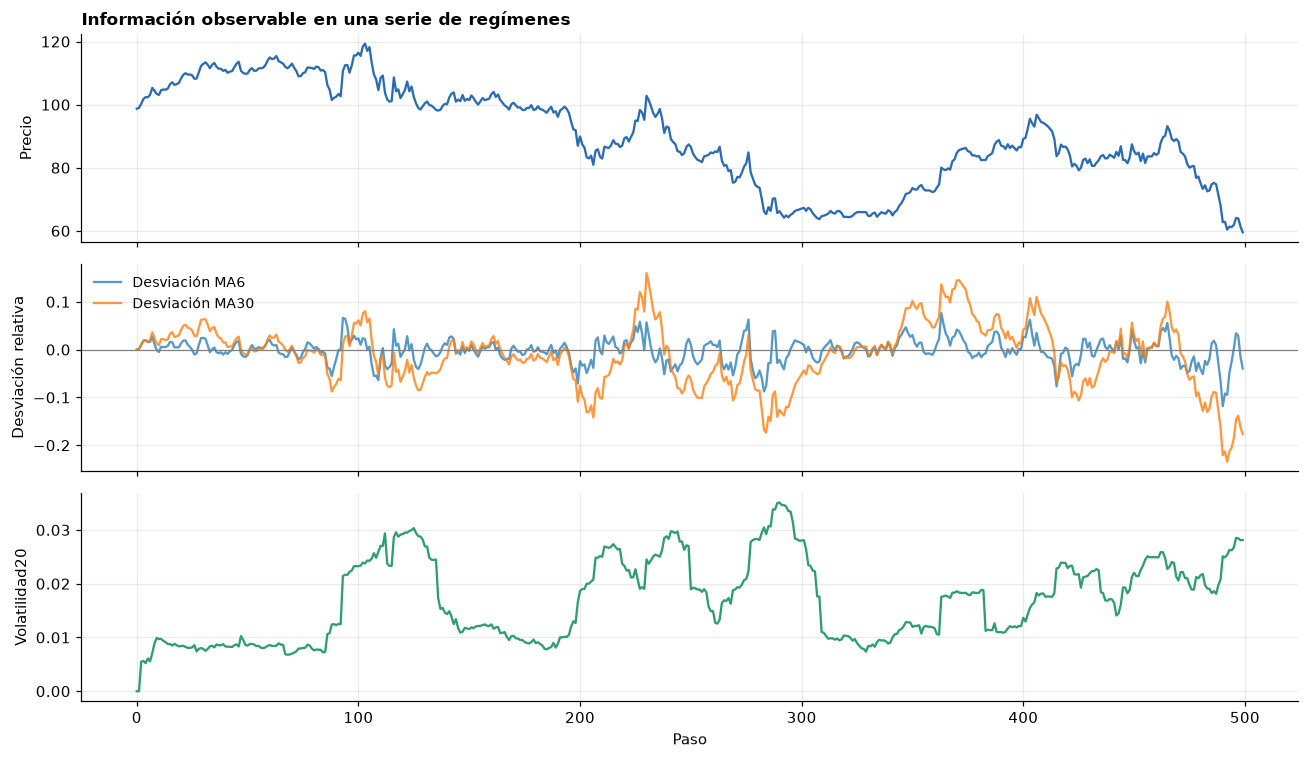

In [3]:
sample = prepare(make_prices("regimenes", N_STEPS, 17))  # serie de train, no seleccionada en test
encoders_demo = {e: fit_encoder(calibration_series("regimenes", N_STEPS), e)
                 for e in ("base", "enriquecido")}
display(pd.DataFrame([
    {"estado": e, "n_estados": enc.n_states,
     "bins": " × ".join(str(len(x)+1) for x in enc.edges) + " × 2 posiciones"}
    for e, enc in encoders_demo.items()]))
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(sample.prices, color=AGENT_COLORS["qlearning"])
axes[0].set_ylabel("Precio"); axes[0].set_title("Información observable en una serie de regímenes", loc="left")
axes[1].plot(sample.features[:, 0], label="Desviación MA6", alpha=.75)
axes[1].plot(sample.features[:, 1], label="Desviación MA30", alpha=.8)
axes[1].axhline(0, color="gray", lw=.8); axes[1].set_ylabel("Desviación relativa"); axes[1].legend()
axes[2].plot(sample.features[:, 2], color=AGENT_COLORS["sarsa"])
axes[2].set_ylabel("Volatilidad20"); axes[2].set_xlabel("Paso")
fig.tight_layout(); figure(fig, "03_estado_features"); plt.show()

### Comprobaciones antes de entrenar

Se comprueba que alterar el futuro no cambie indicadores pasados; que la subclase ejecute las mismas acciones, recompensas, comisiones y balances que el entorno original; y que los índices de la tabla Q sean válidos. El test comprueba además que Q permanezca congelada.

In [4]:
prices = make_prices("regimenes", 160, 7)
changed = prices.copy(); changed[80:] *= 1.5
assert np.array_equal(causal_features(prices)[:80], causal_features(changed)[:80])
env_original, env_extra = SimpleTradingEnv(prices), FeatureTradingEnv(prepare(prices))
env_original.reset(); env_extra.reset()
for action in np.random.default_rng(3).integers(3, size=len(prices)-6):
    o1, r1, d1, t1, info1 = env_original.step(int(action))
    o2, r2, d2, t2, info2 = env_extra.step(int(action))
    assert (r1, d1, t1, info1) == (r2, d2, t2, info2)
    assert np.isclose(o1[0], o2[0]) and o1[1] == o2[-1]
for encoder in encoders_demo.values():
    codes = encoder.codes(sample.features)
    assert codes.min() >= 0 and codes.max() + 1 < encoder.n_states
print("OK: causalidad, contabilidad original e índices del estado.")

OK: causalidad, contabilidad original e índices del estado.


## 3. Mercados extra: hipótesis contrastables

Los dos generadores se añaden al final de `src/markets.py`. Se registran explícitamente al importar `src/extras.py`, de modo que los notebooks 00–02 no amplían sus barridos por el mero hecho de importar `markets`.

| Mercado | Generación | Hipótesis antes de medir |
|---|---|---|
| Tendencia persistente | Log-retorno con media +0,004 o −0,004, ruido σ=0,008 y cambio de signo con p=0,01 | Las tendencias duran unos 100 pasos en promedio; hay señal en la historia reciente. El agente debería aprender a entrar en subidas y salir en bajadas |
| Difusión + saltos | Log-retorno base N(0,0002−σ²/2, σ), σ=0,012; salto independiente con p=0,015 y tamaño N(−0,04, 0,06) | Los saltos no son anticipables con el pasado. Un resultado de no operar puede ser sensato y no se interpretará como predicción de caídas |

Son mecanismos didácticos, no modelos calibrados a un activo. La tendencia empieza alcista, por lo que también se conserva ese sesgo inicial al evaluar. Todos los episodios usan series nuevas de su generador.

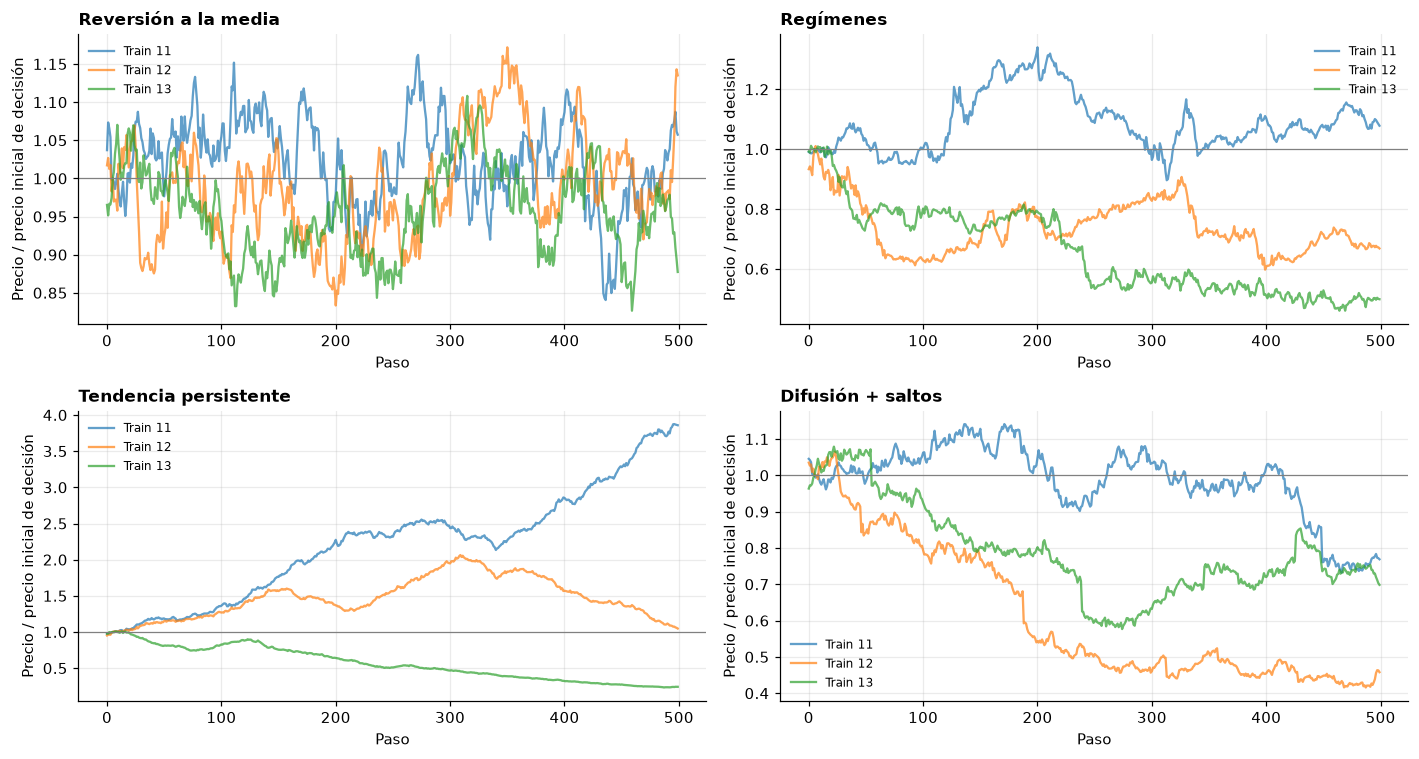

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, market in zip(axes.flat, SYNTHETIC_MARKETS):
    for seed in (11, 12, 13):
        p = make_prices(market, N_STEPS, seed)
        ax.plot(p / p[5], alpha=.7, label=f"Train {seed}")
    ax.axhline(1, color="gray", lw=.8)
    ax.set_title(LABELS[market], loc="left"); ax.set_xlabel("Paso"); ax.set_ylabel("Precio / precio inicial de decisión")
    ax.legend(fontsize=8)
fig.tight_layout(); figure(fig, "03_mercados_extra"); plt.show()

## 4. Serie real y separación temporal

Se usa **SP500**, cierre diario del índice S&P 500 distribuido por [FRED / S&P Dow Jones Indices](https://fred.stlouisfed.org/series/SP500). El CSV local y su JSON de procedencia guardan URL, periodo, fecha de descarga y SHA-256. El notebook no necesita conexión para repetirse; se eliminan festivos sin cotización y no se interpolan precios.

Es un **índice de precios sin dividendos**, no un activo directamente negociable. El experimento simula una exposición fraccionaria al índice con la comisión del taller; omite dividendos, spread, deslizamiento e intereses del efectivo. Es una prueba histórica del algoritmo, no una estrategia operativa validada.

| Split | Fechas | Uso |
|---|---|---|
| Train | 2017–2021 | Cuantiles y episodios: ventanas contiguas aleatorias de 252 cierres, sin barajar los días |
| Validación | 2022–2023 | Diagnóstico fuera de train; política congelada |
| Test | 2024–2025 | Un único recorrido cronológico completo, sin actualizar Q |

Los episodios reales reutilizan ventanas solapadas **solo dentro del train**: no son nuevas historias independientes. Los indicadores de validación/test pueden usar precios anteriores al corte, que ya eran conocidos, pero los bins no se recalculan. Las cinco semillas miden variación del entrenamiento sobre la misma historia; **no equivalen a cinco mercados reales independientes**.

,inicio,fin,cierres
split,,,
train,2017-01-03,2021-12-31,1259
val,2022-01-03,2023-12-29,501
test,2024-01-02,2025-12-31,502


Fuente: https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2017-01-01&coed=2025-12-31
Descarga: 2026-10-28 · 2262 cierres


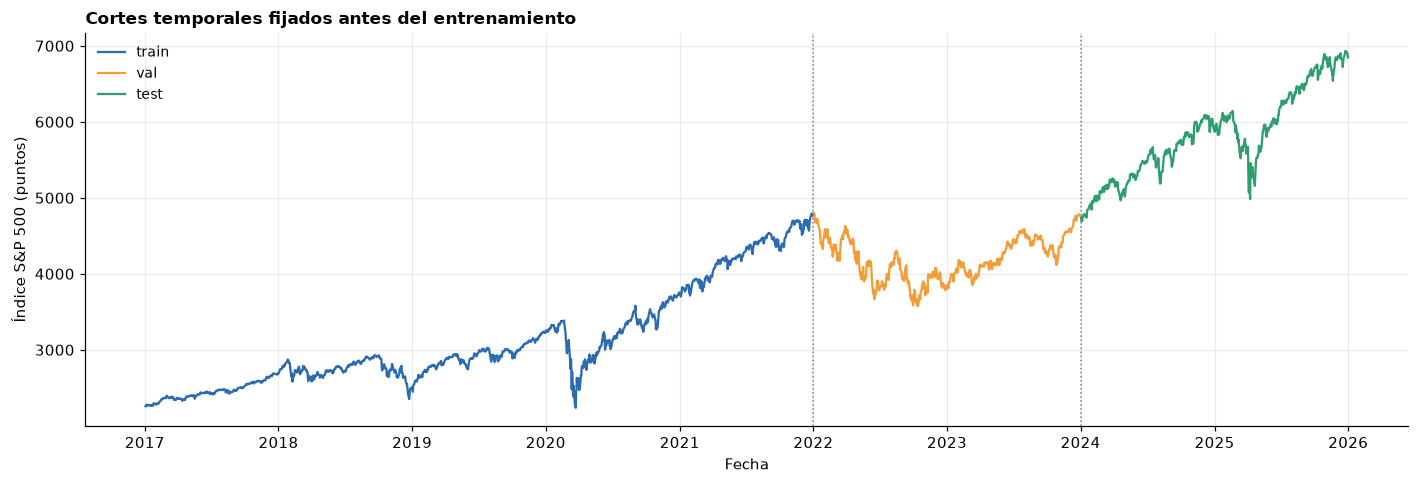

In [6]:
real_df, prepared_real = real_data()
metadata = json.loads((ROOT / "data/sp500_2017_2025.metadata.json").read_text(encoding="utf-8"))
split_rows = []
for split in ("train", "val", "test"):
    idx = real_indices(split)
    split_rows.append(dict(split=split, inicio=real_df.date.iloc[idx[0]].date(),
                           fin=real_df.date.iloc[idx[-1]].date(), cierres=len(idx)))
display(pd.DataFrame(split_rows).set_index("split"))
assert real_indices("train")[-1] < real_indices("val")[0]
assert real_indices("val")[-1] < real_indices("test")[0]
print(f"Fuente: {metadata['source_url']}\nDescarga: {metadata['retrieved_on']} · {metadata['observations']} cierres")

fig, ax = plt.subplots(figsize=(13, 4.5))
colors = {"train": AGENT_COLORS["qlearning"], "val": AGENT_COLORS["buy_hold"], "test": AGENT_COLORS["sarsa"]}
for split in ("train", "val", "test"):
    part = real_df.iloc[real_indices(split)]
    ax.plot(part.date, part.close, color=colors[split], label=split)
for cut in ("2022-01-01", "2024-01-01"):
    ax.axvline(pd.Timestamp(cut), color="gray", ls=":", lw=1)
ax.set_ylabel("Índice S&P 500 (puntos)"); ax.set_xlabel("Fecha")
ax.set_title("Cortes temporales fijados antes del entrenamiento", loc="left"); ax.legend()
fig.tight_layout(); figure(fig, "03_serie_real_splits"); plt.show()

## 5. Entrenamiento y validación

Se entrenan todas las combinaciones con el mismo presupuesto. La caché de `results/cache/03_extras/` identifica configuración, código fuente y datos mediante una huella: cambiar cualquiera de ellos invalida la entrada correspondiente. `RECALCULAR=True` fuerza el recálculo. El modo `NB_QUICK=1` utiliza nombres `_quick` y nunca sobrescribe los resultados completos.

Las curvas son **recompensa durante entrenamiento**, no rentabilidad de test. En datos reales, mejorar sobre ventanas ya reutilizadas puede ser sobreajuste. La convergencia usa la definición común del proyecto y es un indicador descriptivo; no certifica estabilidad ni optimalidad.

In [7]:
validacion = run_training(configs, "03_validacion" + SUF, n_jobs=N_JOBS, recompute=RECALCULAR)
display(validacion.groupby(["mercado", "agente"]).agg(
    retorno_val=("retorno_mediana", "median"), operaciones=("n_trades", "median"),
    estados=("n_estados", "first"), cobertura=("cobertura", "median"),
    segundos=("tiempo_s", "median")).style.format(
        {"retorno_val": "{:+.1%}", "operaciones": "{:.1f}", "cobertura": "{:.1%}", "segundos": "{:.2f}"}))

Entrenamiento/validación: 10/100 · 1 s
Entrenamiento/validación: 20/100 · 1 s
Entrenamiento/validación: 30/100 · 1 s
Entrenamiento/validación: 40/100 · 1 s
Entrenamiento/validación: 50/100 · 1 s
Entrenamiento/validación: 60/100 · 1 s
Entrenamiento/validación: 70/100 · 1 s
Entrenamiento/validación: 80/100 · 1 s
Entrenamiento/validación: 90/100 · 1 s
Entrenamiento/validación: 100/100 · 1 s


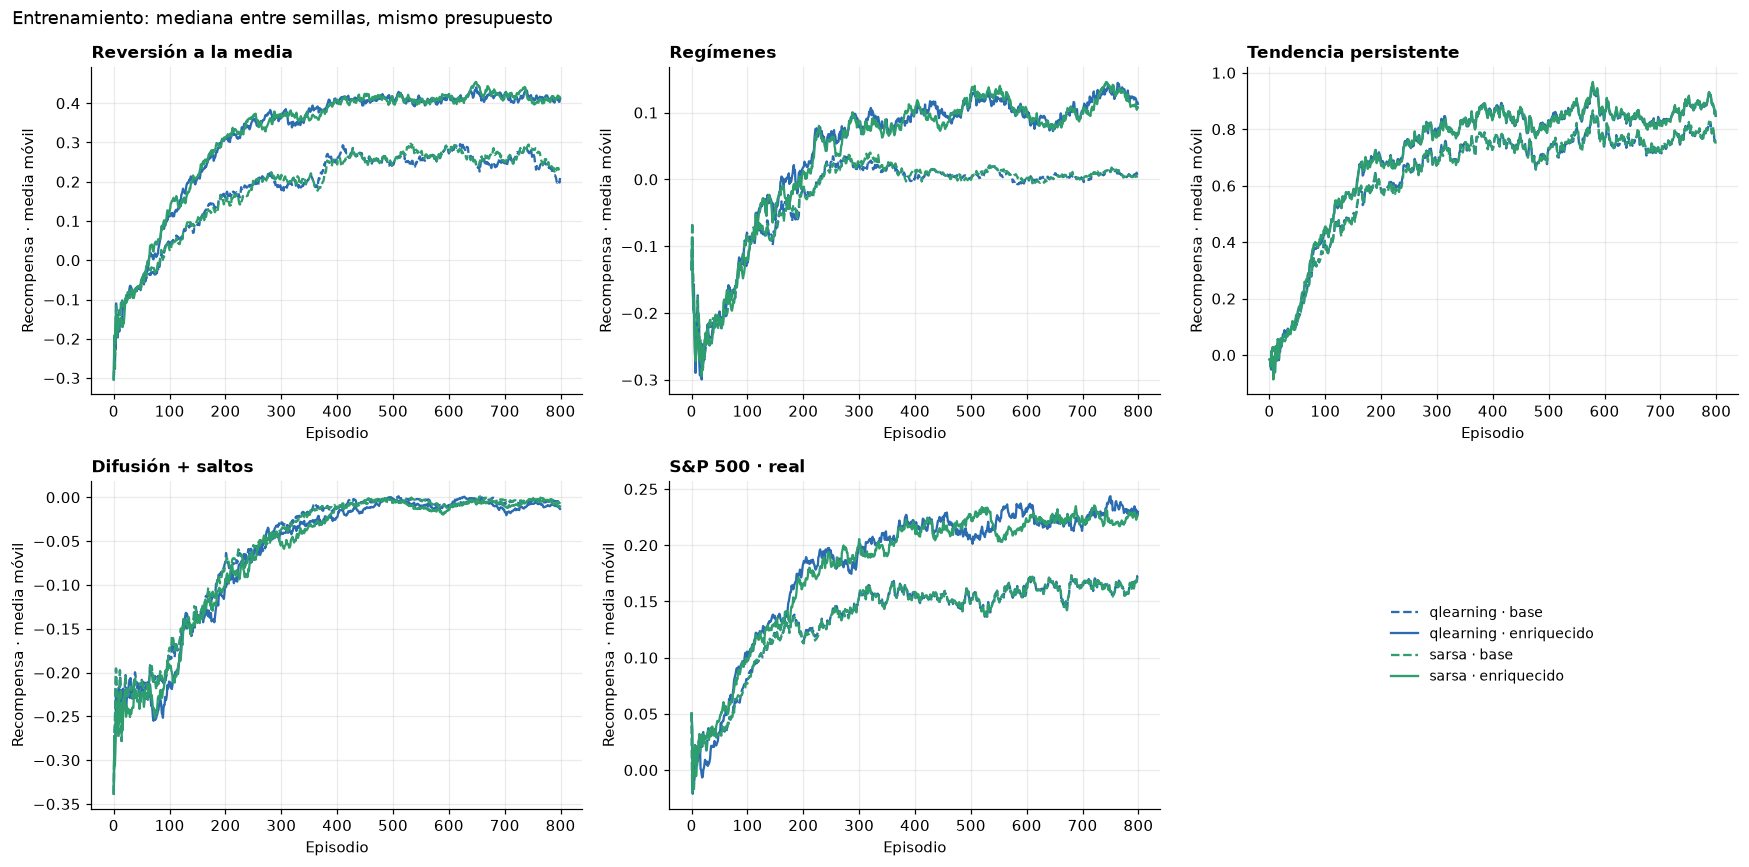

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, market in zip(axes.flat, MARKETS_03):
    for algorithm in ALGORITHMS:
        for state, linestyle in (("base", "--"), ("enriquecido", "-")):
            curves = []
            for cfg in configs:
                if (cfg["mercado"], cfg["algoritmo"], cfg["estado"]) == (market, algorithm, state):
                    _, _, _, rewards = load_model(cfg)
                    curves.append(pd.Series(rewards).rolling(min(50, N_EP), min_periods=1).mean().to_numpy())
            ax.plot(np.median(curves, axis=0), color=AGENT_COLORS[algorithm], ls=linestyle,
                    label=f"{algorithm} · {state}")
    ax.set_title(LABELS[market], loc="left"); ax.set_xlabel("Episodio"); ax.set_ylabel("Recompensa · media móvil")
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
fig.suptitle("Entrenamiento: mediana entre semillas, mismo presupuesto", x=.01, ha="left")
fig.tight_layout(); figure(fig, "03_curvas_aprendizaje"); plt.show()

## 6. Test: rentabilidad, riesgo y operaciones

La tabla principal conserva `RESULT_COLUMNS`: mediana del retorno, media, desviación entre historias, Sharpe por paso, drawdown máximo medio, operaciones y convergencia/tiempo. Primero se calcula cada métrica por entrenamiento; después se toma la mediana entre semillas, igual que en 01–02.

En la serie real hay un único recorrido por política: su **desviación entre historias no es estimable** y queda vacía. El rango entre semillas se informa aparte. El resultado de no operar es cero; batir a buy & hold por permanecer en efectivo no demuestra capacidad predictiva.

In [9]:
semillas, episodios = run_test(configs, suffix=SUF, n_jobs=N_JOBS)
baseline_summary, baseline_paths = baselines(MARKETS_03, n_steps=N_STEPS, n_test=N_TEST)
numeric = [c for c in RESULT_COLUMNS if c not in ("agente", "mercado")]
learned = semillas.groupby(["mercado", "agente"], as_index=False)[numeric].median()
final = pd.concat([learned[RESULT_COLUMNS], baseline_summary[RESULT_COLUMNS]], ignore_index=True)
final = final.sort_values(["mercado", "agente"]).reset_index(drop=True)
save_results(final.to_dict("records"), "03_extras" + SUF)
baseline_paths.to_csv(RESULTS_DIR / f"03_baselines_episodios{SUF}.csv", index=False)
display(final.set_index(["mercado", "agente"])[
    ["retorno_mediana", "retorno_medio", "std", "sharpe", "max_drawdown", "n_trades", "episodios_convergencia", "tiempo_s"]
].style.format({"retorno_mediana": "{:+.1%}", "retorno_medio": "{:+.1%}", "std": "{:.1%}",
                "sharpe": "{:+.3f}", "max_drawdown": "{:.1%}", "n_trades": "{:.1f}", "tiempo_s": "{:.2f}"}, na_rep="—"))
print(f"Guardado: results/03_extras{SUF}.csv · {len(final)} filas")

Test: 10/100
Test: 20/100
Test: 30/100
Test: 40/100
Test: 50/100
Test: 60/100
Test: 70/100
Test: 80/100
Test: 90/100
Test: 100/100


Guardado: results/03_extras.csv · 35 filas


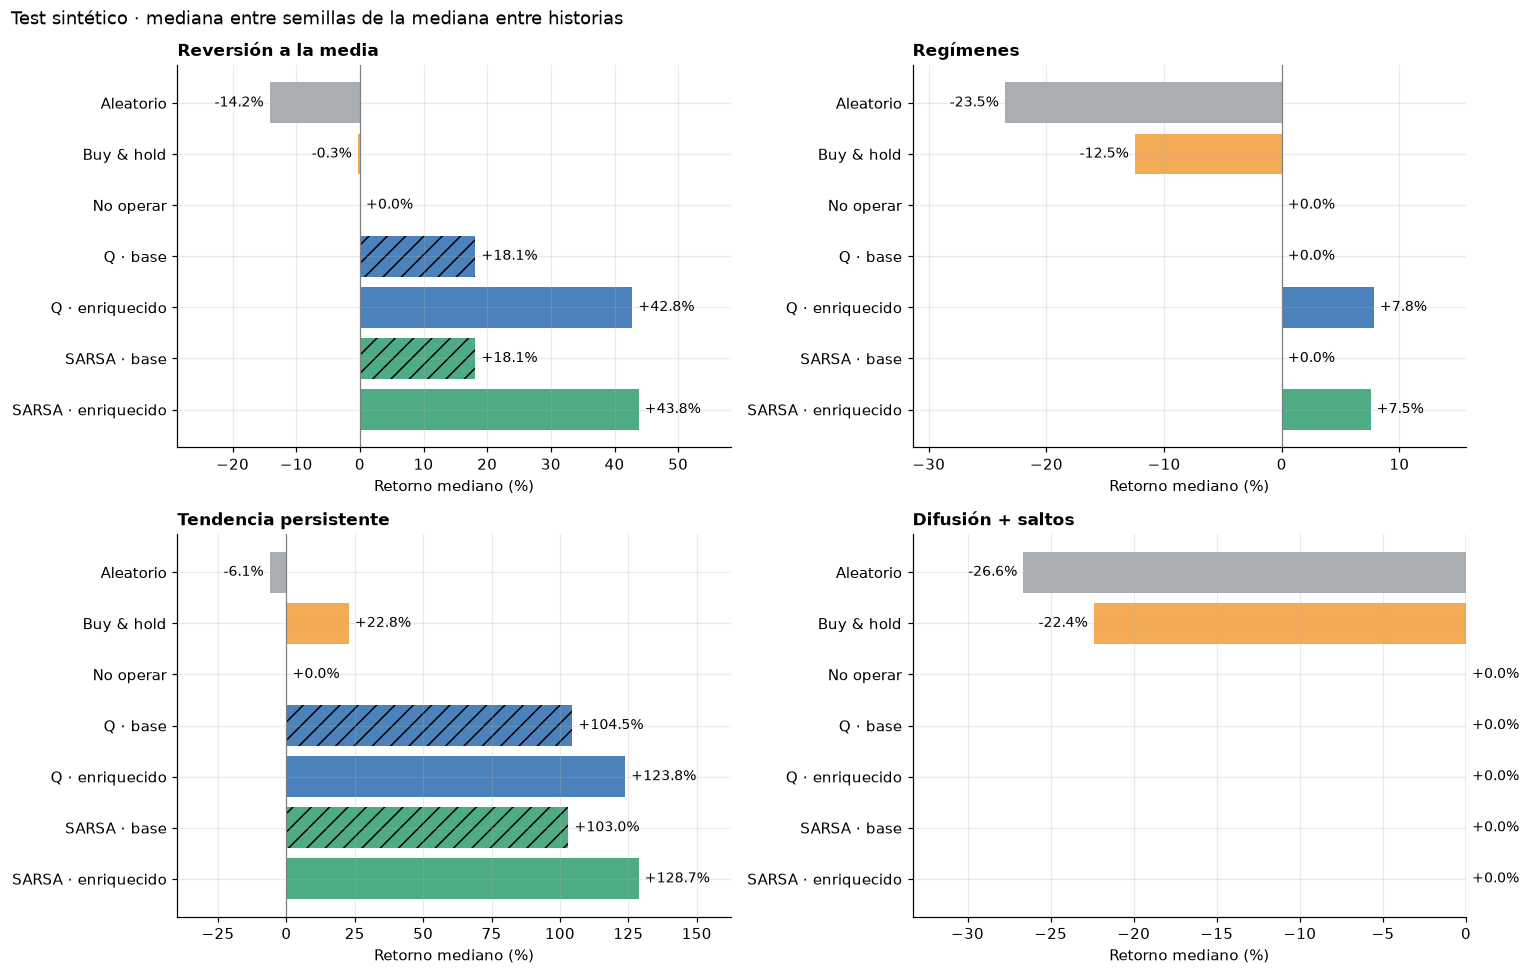

In [10]:
order = ["aleatorio", "buy_hold", "no_operar", "qlearning_base", "qlearning_enriquecido", "sarsa_base", "sarsa_enriquecido"]
names = ["Aleatorio", "Buy & hold", "No operar", "Q · base", "Q · enriquecido", "SARSA · base", "SARSA · enriquecido"]
bar_colors = [AGENT_COLORS["aleatorio"], AGENT_COLORS["buy_hold"], "#6B7280",
              AGENT_COLORS["qlearning"], AGENT_COLORS["qlearning"], AGENT_COLORS["sarsa"], AGENT_COLORS["sarsa"]]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, market in zip(axes.flat, SYNTHETIC_MARKETS):
    sub = final[final.mercado == market].set_index("agente").reindex(order)
    bars = ax.barh(names, 100*sub.retorno_mediana, color=bar_colors, alpha=.85)
    for j in (3, 5):
        bars[j].set_hatch("//")
    for bar, val in zip(bars, sub.retorno_mediana):
        ax.annotate(f"{val:+.1%}", (bar.get_width(), bar.get_y()+bar.get_height()/2),
                    xytext=(4 if val >= 0 else -4, 0), textcoords="offset points",
                    va="center", ha="left" if val >= 0 else "right", fontsize=9)
    ax.axvline(0, color="gray", lw=.8); ax.invert_yaxis(); ax.margins(x=.25)
    ax.set_title(LABELS[market], loc="left"); ax.set_xlabel("Retorno mediano (%)")
fig.suptitle("Test sintético · mediana entre semillas de la mediana entre historias", x=.01, ha="left")
fig.tight_layout(); figure(fig, "03_resultados_sinteticos"); plt.show()

### Base frente a estado enriquecido: qué cambia en los resultados

**Base:** señal de tendencia corta y posición (20 estados). **Enriquecido:** añade distancia a la media de 30 precios y volatilidad de 20 retornos (hasta 180 estados). Se añaden ambos indicadores a la vez; esta comparación no identifica su efecto por separado.

Se enfrentan las variantes **del experimento 03**, con los mismos hiperparámetros, 800 episodios por entrenamiento, cinco semillas y las mismas historias de test en la ejecución completa. Los modelos ajustados de 01–02 tienen otras configuraciones y no son el control de esta prueba. Añadir mercados sintéticos y datos reales amplía la evaluación; no es una característica adicional que reciba el agente.

Las tablas colocan las dos variantes una al lado de la otra. **Δ retorno = enriquecido − base**; positivo significa más rentabilidad. **Reducción del drawdown = base − enriquecido**; positivo significa una caída máxima menor. Ambas diferencias se expresan en **puntos porcentuales (pp)**: pasar del 10 % al 15 % son +5 pp.

El retorno resume primero cada entrenamiento y después toma la mediana entre semillas. En sintéticos, el drawdown es la mediana entre semillas del drawdown máximo medio de las 200 historias; en el S&P 500 es la mediana entre semillas sobre el único recorrido real de 2024–2025. Las diferencias de estas tablas son **restas de los resúmenes**, distintas de la mediana de diferencias emparejadas de la sección siguiente. En modo rápido se usa el presupuesto reducido indicado al inicio.


In [11]:
rows = []
for market in MARKETS_03:
    for algorithm in ALGORITHMS:
        base_row = final.loc[(final.mercado == market) & (final.agente == f"{algorithm}_base")].squeeze()
        rich_row = final.loc[(final.mercado == market) & (final.agente == f"{algorithm}_enriquecido")].squeeze()
        rows.append(dict(
            mercado=market, algoritmo=algorithm,
            retorno_base=base_row.retorno_mediana,
            retorno_enriquecido=rich_row.retorno_mediana,
            delta_retorno_pp=100 * (rich_row.retorno_mediana - base_row.retorno_mediana),
            drawdown_base=base_row.max_drawdown,
            drawdown_enriquecido=rich_row.max_drawdown,
            reduccion_drawdown_pp=100 * (base_row.max_drawdown - rich_row.max_drawdown),
        ))
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS_DIR / f"03_base_vs_enriquecido{SUF}.csv", index=False)

readable = comparison.assign(
    mercado=comparison.mercado.map(LABELS),
    algoritmo=comparison.algoritmo.map({"qlearning": "Q-Learning", "sarsa": "SARSA"}),
).set_index(["mercado", "algoritmo"])
readable.index.names = ["Mercado", "Algoritmo"]
for columns, caption in (
    (["retorno_base", "retorno_enriquecido", "delta_retorno_pp"], "Rentabilidad: positivo en la diferencia significa más retorno"),
    (["drawdown_base", "drawdown_enriquecido", "reduccion_drawdown_pp"], "Caída máxima: positivo en la reducción significa menos riesgo observado"),
):
    labels = {
        "retorno_base": "Retorno base", "retorno_enriquecido": "Retorno enriquecido",
        "delta_retorno_pp": "Δ retorno (pp)", "drawdown_base": "Drawdown base",
        "drawdown_enriquecido": "Drawdown enriquecido",
        "reduccion_drawdown_pp": "Reducción drawdown (pp)",
    }
    view = readable[columns].rename(columns=labels)
    formats = {labels[c]: ("{:+.1f}" if c.endswith("_pp") else "{:.1%}") for c in columns}
    display(view.style.format(formats).map(
        lambda value: "color: #187344" if value > 1e-9 else ("color: #B23A38" if value < -1e-9 else ""),
        subset=[labels[columns[-1]]],
    ).set_caption(caption))

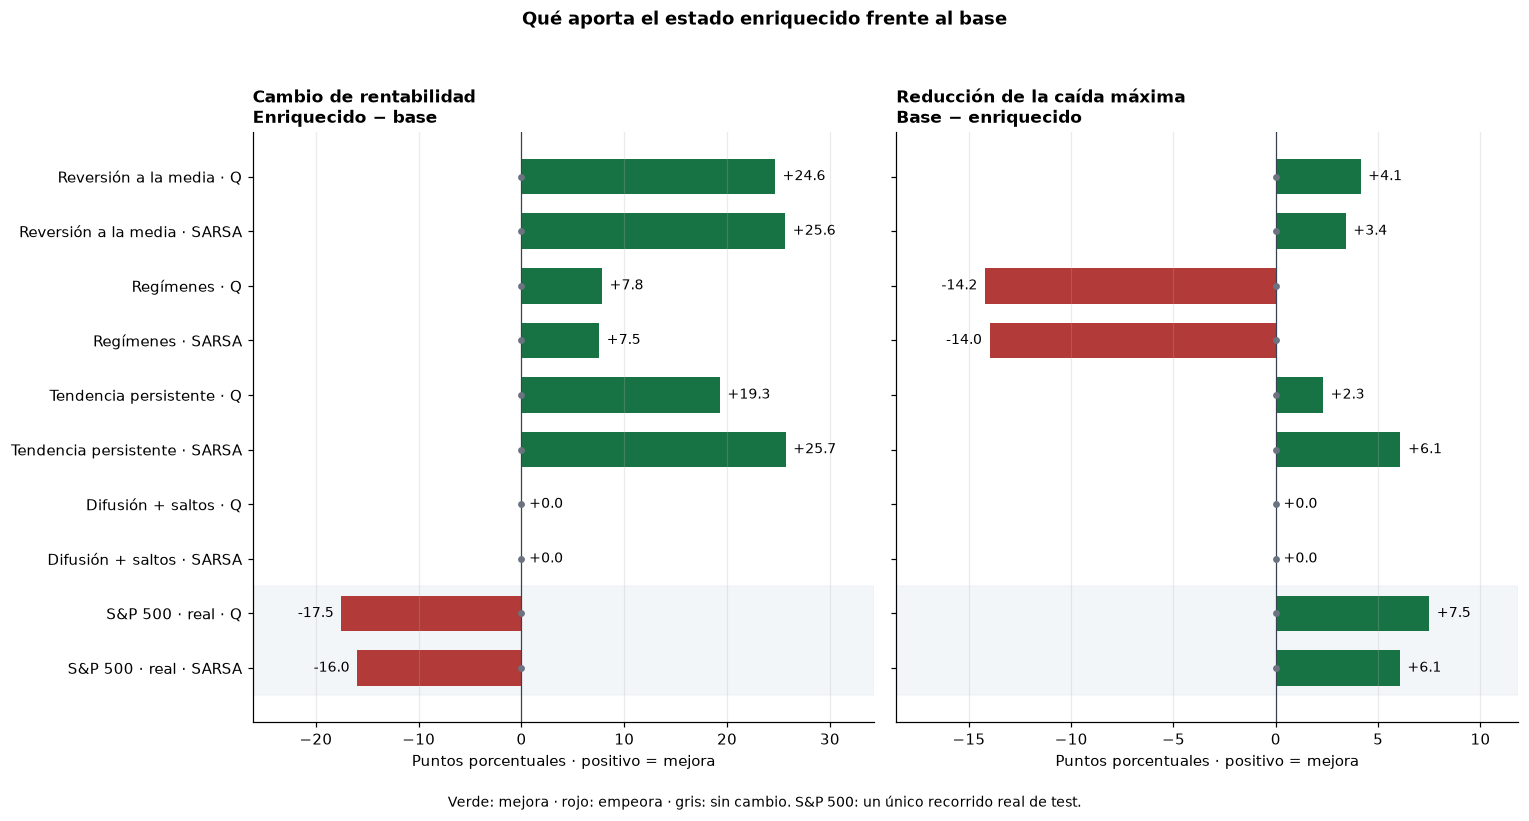

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True)
y = np.arange(len(comparison))
row_labels = [f"{LABELS[r.mercado]} · {'Q' if r.algoritmo == 'qlearning' else 'SARSA'}"
              for r in comparison.itertuples()]
for ax, column, title in (
    (axes[0], "delta_retorno_pp", "Cambio de rentabilidad\nEnriquecido − base"),
    (axes[1], "reduccion_drawdown_pp", "Reducción de la caída máxima\nBase − enriquecido"),
):
    values = comparison[column].to_numpy()
    colors = ["#187344" if value > 1e-9 else ("#B23A38" if value < -1e-9 else "#6B7280") for value in values]
    ax.barh(y, values, color=colors, height=.65)
    ax.scatter(np.zeros(len(y)), y, color="#6B7280", s=12, zorder=3)
    ax.axvline(0, color="#374151", linewidth=.8)
    for yi, value in zip(y, values):
        ax.annotate(f"{value:+.1f}", (value, yi), xytext=(5 if value >= 0 else -5, 0),
                    textcoords="offset points", va="center", ha="left" if value >= 0 else "right", fontsize=9)
    span = max(float(np.ptp(np.r_[values, 0])), 1.)
    ax.set_xlim(min(0, values.min()) - .2 * span, max(0, values.max()) + .2 * span)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Puntos porcentuales · positivo = mejora")
    ax.grid(axis="y", visible=False)
    ax.axhspan(7.5, 9.5, color="#E8EEF5", alpha=.5, zorder=0)
axes[0].set_yticks(y, row_labels)
axes[0].invert_yaxis()
fig.suptitle("Qué aporta el estado enriquecido frente al base", fontweight="bold")
fig.text(.5, .015, "Verde: mejora · rojo: empeora · gris: sin cambio. S&P 500: un único recorrido real de test.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, .04, 1, .95))
figure(fig, "03_base_vs_enriquecido")
plt.show()

In [13]:
report = ["# Comparación directa: modelos base y estado enriquecido", "",
          f"Resultados del experimento 03: {len(SEEDS)} semillas, {N_EP} episodios por entrenamiento y "
          f"{N_TEST} historias sintéticas de test; un único recorrido real de 2024–2025.", "",
          "Base: tendencia corta y posición (20 estados). Enriquecido: añade distancia MA30 y volatilidad20 "
          "(hasta 180 estados). Mismos hiperparámetros, presupuesto e historias de test para ambas variantes. "
          "Los modelos ajustados de 01–02 no son el control de esta comparación.", "",
          "## Rentabilidad", "",
          "| Mercado | Algoritmo | Base | Enriquecido | Δ retorno (pp) |",
          "|---|---|---:|---:|---:|"]
for r in comparison.itertuples():
    algorithm_name = "Q-Learning" if r.algoritmo == "qlearning" else "SARSA"
    report.append(f"| {LABELS[r.mercado]} | {algorithm_name} | {r.retorno_base:+.1%} | "
                  f"{r.retorno_enriquecido:+.1%} | {r.delta_retorno_pp:+.1f} |")
report += ["", "## Caída máxima (drawdown)", "",
           "| Mercado | Algoritmo | Base | Enriquecido | Reducción drawdown (pp) |",
           "|---|---|---:|---:|---:|"]
for r in comparison.itertuples():
    algorithm_name = "Q-Learning" if r.algoritmo == "qlearning" else "SARSA"
    report.append(f"| {LABELS[r.mercado]} | {algorithm_name} | {r.drawdown_base:.1%} | "
                  f"{r.drawdown_enriquecido:.1%} | {r.reduccion_drawdown_pp:+.1f} |")
report += ["", "## Lectura de los resultados", ""]
for r in comparison.itertuples():
    algorithm_name = "Q-Learning" if r.algoritmo == "qlearning" else "SARSA"
    returns = "más retorno" if r.delta_retorno_pp > 1e-9 else ("menos retorno" if r.delta_retorno_pp < -1e-9 else "el mismo retorno")
    risk = "menor drawdown" if r.reduccion_drawdown_pp > 1e-9 else ("mayor drawdown" if r.reduccion_drawdown_pp < -1e-9 else "el mismo drawdown")
    report.append(f"- **{LABELS[r.mercado]} · {algorithm_name}:** {returns} y {risk}.")
report += ["", "Las diferencias son restas de los resúmenes, expresadas en puntos porcentuales: "
           "Δ retorno = enriquecido − base; reducción del drawdown = base − enriquecido. "
           "En ambas columnas, positivo indica mejora. No son las medianas de diferencias emparejadas "
           "ni los intervalos bootstrap de `03_estado_deltas.csv`.", "",
           "El retorno toma primero la mediana entre historias de cada entrenamiento y después la mediana "
           "entre semillas. El drawdown toma la media entre historias de cada entrenamiento y después la "
           "mediana entre semillas. En la serie real solo hay una historia por política: cinco semillas no "
           "equivalen a cinco mercados independientes. Más indicadores no garantizan más rentabilidad; "
           "ambos se incorporan conjuntamente y no se mide su contribución individual.", "",
           f"![Diferencias de retorno y drawdown](figures/03_base_vs_enriquecido{SUF}.png)", ""]
comparison_report = "\n".join(report)
(RESULTS_DIR / f"03_base_vs_enriquecido{SUF}.md").write_text(comparison_report, encoding="utf-8")
display(Markdown("\n".join(report[report.index("## Lectura de los resultados"):report.index("## Lectura de los resultados") + 12])))

## Lectura de los resultados

- **Reversión a la media · Q-Learning:** más retorno y menor drawdown.
- **Reversión a la media · SARSA:** más retorno y menor drawdown.
- **Regímenes · Q-Learning:** más retorno y mayor drawdown.
- **Regímenes · SARSA:** más retorno y mayor drawdown.
- **Tendencia persistente · Q-Learning:** más retorno y menor drawdown.
- **Tendencia persistente · SARSA:** más retorno y menor drawdown.
- **Difusión + saltos · Q-Learning:** el mismo retorno y el mismo drawdown.
- **Difusión + saltos · SARSA:** el mismo retorno y el mismo drawdown.
- **S&P 500 · real · Q-Learning:** menos retorno y menor drawdown.
- **S&P 500 · real · SARSA:** menos retorno y menor drawdown.

### ¿Cuánto aporta el estado? Comparación emparejada

Cada política se evalúa en las mismas historias de test. Para cada historia se toma la mediana del retorno entre semillas y se resta **enriquecido − base**. La tabla muestra la mediana de esas diferencias, un intervalo bootstrap del 95 % (2 000 remuestreos de historias) y la fracción de historias donde mejora.

La mediana de diferencias no tiene por qué coincidir con la diferencia de medianas de la tabla anterior. El intervalo es **condicional a las cinco políticas entrenadas**: no incluye toda la incertidumbre de volver a entrenar ni corrige por comparaciones múltiples. No se aplica este bootstrap a la única historia real.

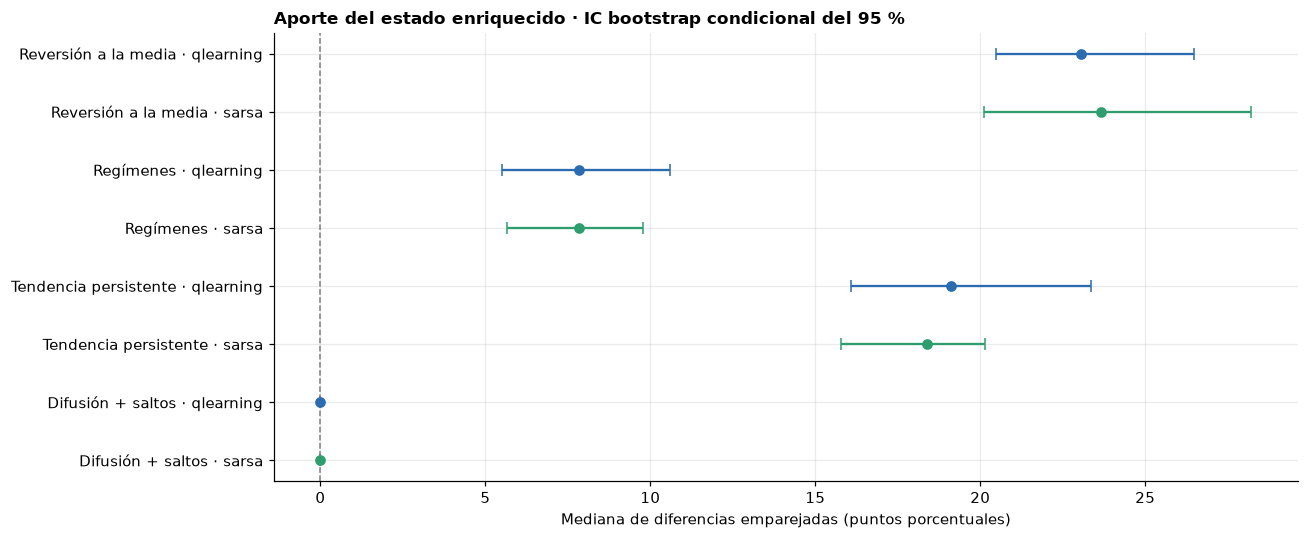

In [14]:
deltas = paired_state_effect(episodios)
deltas.to_csv(RESULTS_DIR / f"03_estado_deltas{SUF}.csv", index=False)
display(deltas.set_index(["mercado", "algoritmo"]).style.format(
    {"delta_mediana": "{:+.1%}", "ic95_inf": "{:+.1%}", "ic95_sup": "{:+.1%}", "fraccion_mejora": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(12, 5))
for y, row in enumerate(deltas.itertuples()):
    ax.errorbar(100*row.delta_mediana, y,
                xerr=[[100*(row.delta_mediana-row.ic95_inf)], [100*(row.ic95_sup-row.delta_mediana)]],
                fmt="o", capsize=4, color=AGENT_COLORS[row.algoritmo])
ax.set_yticks(range(len(deltas)), [f"{LABELS[r.mercado]} · {r.algoritmo}" for r in deltas.itertuples()])
ax.axvline(0, color="gray", ls="--", lw=1); ax.invert_yaxis()
ax.set_xlabel("Mediana de diferencias emparejadas (puntos porcentuales)")
ax.set_title("Aporte del estado enriquecido · IC bootstrap condicional del 95 %", loc="left")
fig.tight_layout(); figure(fig, "03_aporte_estado"); plt.show()

### Cobertura del estado y coste del aprendizaje

La cobertura es la proporción de estados que se han visitado al menos una vez durante train, no la proporción de acciones bien aprendidas. Una cobertura alta tampoco garantiza suficientes visitas en las celdas infrecuentes. Se muestran mediana de visitas por celda y tiempo; este último incluye contención de los procesos y sirve como orientación en esta máquina.

In [15]:
coverage = semillas.groupby(["mercado", "estado"]).agg(
    estados=("n_estados", "first"), cobertura=("cobertura", "median"),
    visitas_mediana=("visitas_mediana", "median"), tiempo_s=("tiempo_s", "median"))
display(coverage.style.format({"cobertura": "{:.1%}", "visitas_mediana": "{:.0f}", "tiempo_s": "{:.2f}"}))
coverage.to_csv(RESULTS_DIR / f"03_cobertura{SUF}.csv")

## 7. Serie real: recorrido completo y bloques temporales

El gráfico de balance utiliza la **semilla 0, fijada de antemano**, no la que mejor salió en test. Las políticas están congeladas. Cada curva comienza con 1 000 y utiliza el mismo cierre inicial; se comparan también buy & hold y efectivo.

El resumen real informa el retorno completo y su rango entre entrenamientos. Después se reinicia el capital en bloques consecutivos de hasta 63 retornos diarios (se conserva un último bloque si tiene al menos 21). Estos bloques no solapan retornos, pero siguen siendo periodos relacionados de la misma historia. Se utilizan para mostrar heterogeneidad temporal, no como 200 muestras independientes ni como sustituto del recorrido completo.

,retorno_mediana,minimo_semilla,maximo_semilla,drawdown,operaciones
agente,,,,,
qlearning_base,+45.9%,+45.9%,+45.9%,18.9%,1
qlearning_enriquecido,+28.3%,+27.7%,+46.4%,11.4%,79
sarsa_base,+45.9%,+45.9%,+45.9%,18.9%,1
sarsa_enriquecido,+29.9%,+17.8%,+38.5%,12.8%,77


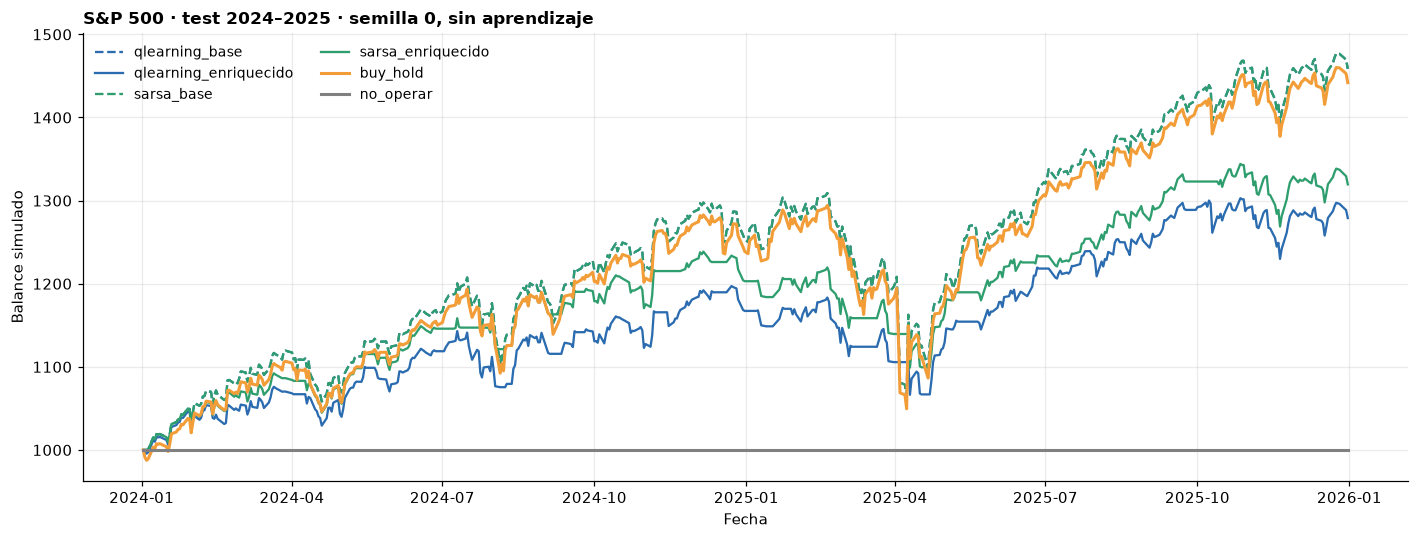

In [16]:
real_summary = semillas[semillas.mercado == "sp500_real"].groupby("agente").agg(
    retorno_mediana=("retorno_mediana", "median"), minimo_semilla=("retorno_mediana", "min"),
    maximo_semilla=("retorno_mediana", "max"), drawdown=("max_drawdown", "median"),
    operaciones=("n_trades", "median"))
display(real_summary.style.format({"retorno_mediana": "{:+.1%}", "minimo_semilla": "{:+.1%}",
                                  "maximo_semilla": "{:+.1%}", "drawdown": "{:.1%}", "operaciones": "{:.0f}"}))
test_real = evaluation_series("sp500_real", "test")[0]
fig, ax = plt.subplots(figsize=(13, 5))
block_rows = []
for cfg in configs:
    if cfg["mercado"] != "sp500_real":
        continue
    agent, encoder, row, _ = load_model(cfg)
    blocks = real_blocks(agent, encoder, seed=cfg["seed"])
    block_rows.extend(blocks.assign(agente=row["agente"], seed=cfg["seed"]).to_dict("records"))
    if cfg["seed"] == 0:
        _, balances, _, _ = run_extra_episode(test_real, agent, encoder)
        ax.plot(pd.to_datetime(test_real.dates[5:]), balances, color=AGENT_COLORS[cfg["algoritmo"]],
                ls="--" if cfg["estado"] == "base" else "-", label=row["agente"])
real_encoder = fit_encoder(calibration_series("sp500_real"))
for name, agent in (("buy_hold", BuyHoldAgent()), ("no_operar", CashAgent())):
    _, balances, _, _ = run_extra_episode(test_real, agent, real_encoder)
    ax.plot(pd.to_datetime(test_real.dates[5:]), balances,
            color=AGENT_COLORS["buy_hold"] if name == "buy_hold" else "gray", label=name, lw=2)
    blocks = real_blocks(agent, real_encoder)
    block_rows.extend(blocks.assign(agente=name, seed=-1).to_dict("records"))
ax.set_title("S&P 500 · test 2024–2025 · semilla 0, sin aprendizaje", loc="left")
ax.set_ylabel("Balance simulado"); ax.set_xlabel("Fecha"); ax.legend(ncol=2)
fig.tight_layout(); figure(fig, "03_real_balance"); plt.show()
blocks = pd.DataFrame(block_rows)
blocks.to_csv(RESULTS_DIR / f"03_real_bloques{SUF}.csv", index=False)

,agente,buy_hold,no_operar,qlearning_base,qlearning_enriquecido,sarsa_base,sarsa_enriquecido
fecha_inicio,fecha_fin,,,,,,
2024-01-02,2024-04-03,+9.8%,+0.0%,+11.0%,+6.7%,+11.0%,+6.6%
2024-04-03,2024-07-03,+6.1%,+0.0%,+6.1%,+6.8%,+6.1%,+7.9%
2024-07-03,2024-10-02,+3.0%,+0.0%,+2.5%,-0.3%,+2.5%,+0.4%
2024-10-02,2025-01-02,+2.7%,+0.0%,+2.7%,+1.8%,+2.7%,+2.4%
2025-01-02,2025-04-04,-13.6%,+0.0%,-13.6%,-6.2%,-13.6%,-8.7%
2025-04-04,2025-07-08,+22.6%,+0.0%,+22.6%,+10.1%,+22.6%,+12.3%
2025-07-08,2025-10-06,+8.2%,+0.0%,+8.2%,+7.6%,+8.2%,+7.1%
2025-10-06,2025-12-31,+1.5%,+0.0%,+1.8%,-0.6%,+1.8%,-0.6%


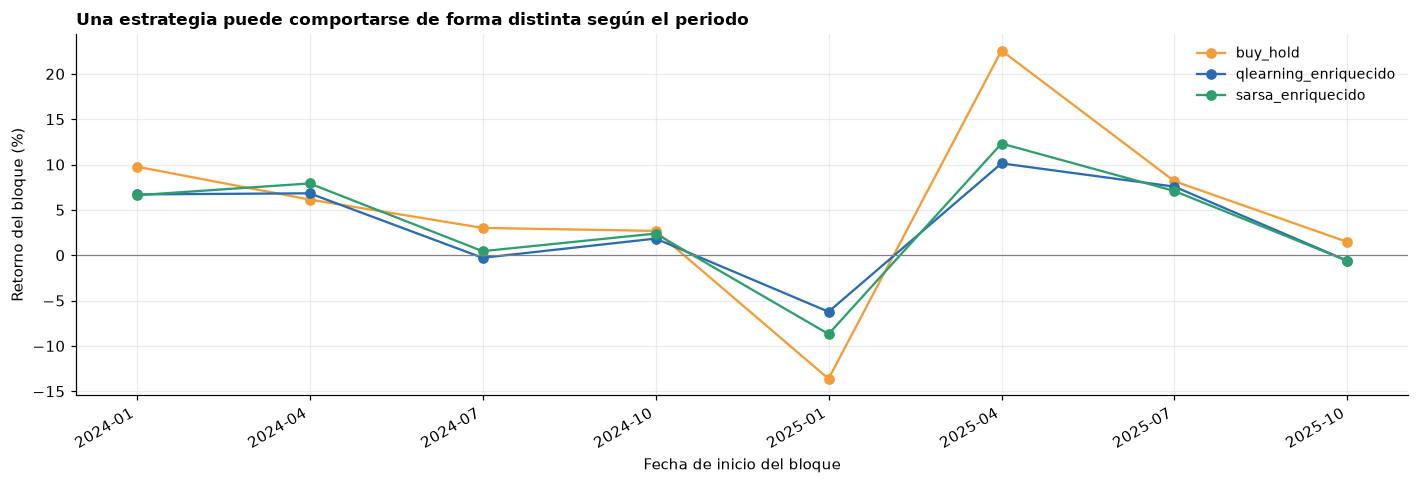

In [17]:
block_table = blocks.pivot_table(index=["fecha_inicio", "fecha_fin"], columns="agente", values="retorno", aggfunc="median")
display(block_table.style.format("{:+.1%}").set_caption("Retornos por bloque: mediana entre semillas; capital reiniciado en cada bloque"))
fig, ax = plt.subplots(figsize=(13, 4.5))
for agent_name in ["buy_hold", "qlearning_enriquecido", "sarsa_enriquecido"]:
    algo = agent_name.split("_")[0]
    color = AGENT_COLORS["buy_hold"] if agent_name == "buy_hold" else AGENT_COLORS[algo]
    ax.plot(np.arange(len(block_table)), 100*block_table[agent_name], marker="o", color=color, label=agent_name)
ax.axhline(0, color="gray", lw=.8)
ax.set_xticks(np.arange(len(block_table)), [a[:7] for a, b in block_table.index], rotation=30, ha="right")
ax.set_ylabel("Retorno del bloque (%)"); ax.set_xlabel("Fecha de inicio del bloque")
ax.set_title("Una estrategia puede comportarse de forma distinta según el periodo", loc="left"); ax.legend()
fig.tight_layout(); figure(fig, "03_real_bloques"); plt.show()

## 8. Conclusiones calculadas a partir de esta ejecución

Las conclusiones siguientes se generan con los resultados anteriores: también se conserva una versión Markdown en `results/03_conclusiones.md`. Un resultado de no operar o una mejora no concluyente se informa como tal.

In [18]:
lines = ["# 03 · Conclusiones de los extras", "",
         f"Ejecución {'rápida de comprobación' if QUICK else 'completa'}: {len(SEEDS)} semillas, {N_EP} episodios, "
         f"{N_TEST} historias sintéticas de test. Configuración fija y comparación emparejada.", "",
         "## Estado enriquecido", ""]
for r in deltas.itertuples():
    verdict = ("mejora con intervalo por encima de cero" if r.ic95_inf > 0 else
               "empeora con intervalo por debajo de cero" if r.ic95_sup < 0 else
               "sin mejora concluyente con este protocolo")
    lines.append(f"- **{LABELS[r.mercado]} · {r.algoritmo}:** {verdict}; mediana del delta {100*r.delta_mediana:+.1f} puntos porcentuales, "
                 f"IC95 condicional [{100*r.ic95_inf:+.1f}, {100*r.ic95_sup:+.1f}] puntos.")
lines += ["", "Los intervalos condicionan a las políticas entrenadas y no corrigen comparaciones múltiples. "
          "El estado crece de 20 a 180 celdas sin aumentar el presupuesto; esto mezcla información adicional y coste estadístico.",
          "", "## Mercados extra", ""]
for m in ("tendencia_persistente", "saltos"):
    sub = final[final.mercado == m].set_index("agente")
    q, sa, bh = [float(sub.loc[a, "retorno_mediana"]) for a in ("qlearning_enriquecido", "sarsa_enriquecido", "buy_hold")]
    lines.append(f"- **{LABELS[m]}:** Q enriquecido {q:+.1%}, SARSA enriquecido {sa:+.1%}, buy & hold {bh:+.1%}; efectivo 0 %.")
lines += ["", "La tendencia contiene persistencia aprovechable; los saltos son independientes. "
          "Superar buy & hold permaneciendo fuera no demuestra anticipación de saltos.", "", "## Serie real", ""]
bh_real = float(final[(final.mercado == "sp500_real") & (final.agente == "buy_hold")].retorno_mediana.iloc[0])
lines.append(f"- Buy & hold en el recorrido completo 2024–2025: **{bh_real:+.1%}**.")
for name in ("qlearning_base", "qlearning_enriquecido", "sarsa_base", "sarsa_enriquecido"):
    r = real_summary.loc[name]
    lines.append(f"- **{name}:** mediana {r.retorno_mediana:+.1%}, rango entre semillas "
                 f"[{r.minimo_semilla:+.1%}, {r.maximo_semilla:+.1%}], drawdown mediano {r.drawdown:.1%}, "
                 f"{r.operaciones:.0f} operaciones.")
for algorithm in ALGORITHMS:
    base_r = real_summary.loc[f"{algorithm}_base"]
    rich_r = real_summary.loc[f"{algorithm}_enriquecido"]
    direction = "más" if rich_r.retorno_mediana > base_r.retorno_mediana else "menos" if rich_r.retorno_mediana < base_r.retorno_mediana else "el mismo"
    risk = "menor" if rich_r.drawdown < base_r.drawdown else "mayor o igual"
    lines.append(f"- **Balance de la ampliación en {algorithm}:** {direction} retorno mediano y {risk} drawdown. "
                 "La evaluación exige leer ambas medidas conjuntamente.")
if all(real_summary.loc[f"{a}_base", "operaciones"] <= 1 for a in ALGORITHMS):
    lines += ["", "Los agentes base hacen como máximo una operación en mediana. Su diferencia frente a buy & hold "
              "puede proceder del momento de entrada; no implica haber aprendido una estrategia activa de anticipación."]
lines += ["", "La historia real de test es única y los entrenamientos reutilizan ventanas del pasado. "
          "No se puede inferir una ventaja persistente a partir de estos dos años ni de cinco semillas sobre los mismos precios. "
          "Los bloques muestran variación temporal, no nuevas historias independientes.",
          "", "## Límites y lectura crítica", "",
          "- Se conserva la recompensa del taller: suma retornos simples con comisión, mientras que el balance compone. "
          "Una mayor recompensa de entrenamiento no garantiza mayor rentabilidad final.",
          "- Los indicadores ampliados no garantizan un estado markoviano. La comparación no es una búsqueda exhaustiva de estados o hiperparámetros.",
          "- Se añaden MA30 y volatilidad conjuntamente: esta prueba no permite atribuir la mejora a cada indicador por separado.",
          "- La convergencia es un resumen descriptivo de la curva; puede reflejar el descenso de exploración y no una estrategia estable.",
          "- La evaluación real usa el índice de precios, sin dividendos, spread, deslizamiento ni intereses del efectivo; "
          "no es un activo directamente negociable y no constituye validación operativa.",
          "", "Fuente de la serie real: https://fred.stlouisfed.org/series/SP500. "
          f"{metadata['observations']} cierres; huella de los datos: `{metadata['sha256']}`."]
conclusions = "\n".join(lines)
(RESULTS_DIR / f"03_conclusiones{SUF}.md").write_text(conclusions + "\n", encoding="utf-8")
display(Markdown(conclusions))

manifest = dict(mode="quick" if QUICK else "full", configs=configs,
                source_fingerprint=code_fingerprint(), data=metadata,
                synthetic_test_series=N_TEST, real_test_paths=1, seeds=SEEDS,
                python=sys.version, numpy=np.__version__, pandas=pd.__version__)
(RESULTS_DIR / f"03_protocolo{SUF}.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
assert final[RESULT_COLUMNS].shape == (35, len(RESULT_COLUMNS))
assert final[["agente", "mercado"]].duplicated().sum() == 0
assert np.isfinite(final[["retorno_mediana", "retorno_medio", "sharpe", "max_drawdown", "n_trades"]]).all().all()
print("OK: tabla común, resultados por semilla/episodio, controles, figuras y protocolo guardados.")

# 03 · Conclusiones de los extras

Ejecución completa: 5 semillas, 800 episodios, 200 historias sintéticas de test. Configuración fija y comparación emparejada.

## Estado enriquecido

- **Reversión a la media · qlearning:** mejora con intervalo por encima de cero; mediana del delta +23.1 puntos porcentuales, IC95 condicional [+20.5, +26.5] puntos.
- **Reversión a la media · sarsa:** mejora con intervalo por encima de cero; mediana del delta +23.7 puntos porcentuales, IC95 condicional [+20.1, +28.2] puntos.
- **Regímenes · qlearning:** mejora con intervalo por encima de cero; mediana del delta +7.8 puntos porcentuales, IC95 condicional [+5.5, +10.6] puntos.
- **Regímenes · sarsa:** mejora con intervalo por encima de cero; mediana del delta +7.8 puntos porcentuales, IC95 condicional [+5.7, +9.8] puntos.
- **Tendencia persistente · qlearning:** mejora con intervalo por encima de cero; mediana del delta +19.1 puntos porcentuales, IC95 condicional [+16.1, +23.4] puntos.
- **Tendencia persistente · sarsa:** mejora con intervalo por encima de cero; mediana del delta +18.4 puntos porcentuales, IC95 condicional [+15.8, +20.1] puntos.
- **Difusión + saltos · qlearning:** sin mejora concluyente con este protocolo; mediana del delta +0.0 puntos porcentuales, IC95 condicional [+0.0, +0.0] puntos.
- **Difusión + saltos · sarsa:** sin mejora concluyente con este protocolo; mediana del delta +0.0 puntos porcentuales, IC95 condicional [+0.0, +0.0] puntos.

Los intervalos condicionan a las políticas entrenadas y no corrigen comparaciones múltiples. El estado crece de 20 a 180 celdas sin aumentar el presupuesto; esto mezcla información adicional y coste estadístico.

## Mercados extra

- **Tendencia persistente:** Q enriquecido +123.8%, SARSA enriquecido +128.7%, buy & hold +22.8%; efectivo 0 %.
- **Difusión + saltos:** Q enriquecido +0.0%, SARSA enriquecido +0.0%, buy & hold -22.4%; efectivo 0 %.

La tendencia contiene persistencia aprovechable; los saltos son independientes. Superar buy & hold permaneciendo fuera no demuestra anticipación de saltos.

## Serie real

- Buy & hold en el recorrido completo 2024–2025: **+44.2%**.
- **qlearning_base:** mediana +45.9%, rango entre semillas [+45.9%, +45.9%], drawdown mediano 18.9%, 1 operaciones.
- **qlearning_enriquecido:** mediana +28.3%, rango entre semillas [+27.7%, +46.4%], drawdown mediano 11.4%, 79 operaciones.
- **sarsa_base:** mediana +45.9%, rango entre semillas [+45.9%, +45.9%], drawdown mediano 18.9%, 1 operaciones.
- **sarsa_enriquecido:** mediana +29.9%, rango entre semillas [+17.8%, +38.5%], drawdown mediano 12.8%, 77 operaciones.
- **Balance de la ampliación en qlearning:** menos retorno mediano y menor drawdown. La evaluación exige leer ambas medidas conjuntamente.
- **Balance de la ampliación en sarsa:** menos retorno mediano y menor drawdown. La evaluación exige leer ambas medidas conjuntamente.

Los agentes base hacen como máximo una operación en mediana. Su diferencia frente a buy & hold puede proceder del momento de entrada; no implica haber aprendido una estrategia activa de anticipación.

La historia real de test es única y los entrenamientos reutilizan ventanas del pasado. No se puede inferir una ventaja persistente a partir de estos dos años ni de cinco semillas sobre los mismos precios. Los bloques muestran variación temporal, no nuevas historias independientes.

## Límites y lectura crítica

- Se conserva la recompensa del taller: suma retornos simples con comisión, mientras que el balance compone. Una mayor recompensa de entrenamiento no garantiza mayor rentabilidad final.
- Los indicadores ampliados no garantizan un estado markoviano. La comparación no es una búsqueda exhaustiva de estados o hiperparámetros.
- Se añaden MA30 y volatilidad conjuntamente: esta prueba no permite atribuir la mejora a cada indicador por separado.
- La convergencia es un resumen descriptivo de la curva; puede reflejar el descenso de exploración y no una estrategia estable.
- La evaluación real usa el índice de precios, sin dividendos, spread, deslizamiento ni intereses del efectivo; no es un activo directamente negociable y no constituye validación operativa.

Fuente de la serie real: https://fred.stlouisfed.org/series/SP500. 2262 cierres; huella de los datos: `39dc70d1cc353c0e89a1ef9d6c99be00930859a6460a553d2ef2ac5a8496f1dd`.

OK: tabla común, resultados por semilla/episodio, controles, figuras y protocolo guardados.


## 9. Anexo · ¿Se sostienen las conclusiones? Pruebas de robustez

Los límites del §8 dejan varias preguntas abiertas. Este anexo las contrasta con **el mismo protocolo** de las secciones anteriores (indicadores causales, bins de train, historias de test, semillas y presupuesto) y cambia **un solo factor cada vez**:

| § | Pregunta | Qué cambia |
|---|---|---|
| 9.1 | ¿Qué indicador aporta la mejora? | Estado: base, +MA30, +volatilidad, ambos |
| 9.2 | ¿El estado grande está infraentrenado? | Episodios: ×1, ×2, ×4 |
| 9.3 | ¿Gana donde no hay nada que ganar? | Placebos: browniano y S&P 500 con retornos barajados |
| 9.4 | ¿Cuánta comisión aguanta cada estrategia? | Comisión: 0 % a 0,5 % por operación |
| 9.5 | ¿Importa el algoritmo TD? | Q-Learning, SARSA, Expected SARSA, Double Q-Learning |
| 9.6 | ¿Importa que la recompensa sume y el capital componga? | Recompensa del taller frente a log(balance) |
| 9.7 | ¿Se repite en otros años reales? | Walk-forward anual 2019–2025 |
| 9.8 | ¿Qué ha aprendido el estado enriquecido? | Mapa de la política greedy |

Salvo el factor que se estudia, todo es igual que en el §1: **Q-Learning, estado enriquecido, comisión del 0,1 %, recompensa del taller**, α=0,001, γ=0,9, ε 1→0,01 y 800 episodios. Las configuraciones se fijan antes de evaluar y no se elige ninguna mirando el test, así que el anexo no usa validación. El código está en `src/extras_anexo.py`, que reutiliza `src/extras.py` sin modificarlo; las salidas son `results/03_anexo*` y las figuras `03_anexo_*.png`.

In [19]:
from src.extras_anexo import (COLUMNS, STATE_LABELS, ALGORITHM_LABELS, ALGORITHMS as ALGORITHMS_ANEXO,
                              run_anexo, baseline, exposure_map)

ANEXO = dict(BASE, algoritmo="qlearning", estado="enriquecido", coste=0.001, recompensa="taller", anio=0)
MERCADOS_ANEXO = ["reversion_media", "regimenes", "tendencia_persistente", "sp500_real"]
COSTES = [0.0, 0.0005, 0.001, 0.0025, 0.005]
YEARS = list(range(2019, 2026))
LABELS_ANEXO = {**LABELS, "tendencia_ciclo": "Tendencia + ciclo", "browniano": "Browniano",
                "sp500_barajado": "S&P 500 · barajado", "sp500_anual": "S&P 500 · año"}

def variant(experiment, **changes):
    """Una configuración del §1 con un único factor cambiado, para cada semilla."""
    return [dict(ANEXO, experimento=experiment, **changes, seed=s) for s in SEEDS]

anexo_configs = []
for m in MERCADOS_ANEXO:
    for e in COLUMNS:
        anexo_configs += variant("indicadores", mercado=m, estado=e)
    for k in (1, 2, 4):
        anexo_configs += variant("presupuesto", mercado=m, n_episodes=k * N_EP)
    for a in ALGORITHMS_ANEXO:
        anexo_configs += variant("algoritmos", mercado=m, algoritmo=a)
for m in ("browniano", "sp500_barajado"):
    for e in ("base", "enriquecido"):
        anexo_configs += variant("placebo", mercado=m, estado=e)
for m in MERCADOS_ANEXO[:3]:
    for c in COSTES:
        anexo_configs += variant("comision", mercado=m, coste=c)
for m in ["tendencia_ciclo", *MERCADOS_ANEXO]:
    for r in ("taller", "log"):
        anexo_configs += variant("recompensa", mercado=m, recompensa=r)
for y in YEARS:
    for e in ("base", "enriquecido"):
        anexo_configs += variant("walk_forward", mercado="sp500_anual", anio=y, estado=e)

anexo = run_anexo(anexo_configs, "03_anexo_semillas" + SUF, n_jobs=N_JOBS, recompute=RECALCULAR)
print(f"{len(anexo_configs)} filas de experimento · {anexo.id.nunique()} entrenamientos distintos "
      "(los que coinciden entre experimentos se entrenan una vez)")

Anexo: 25/360 entrenamientos · 2 s


Anexo: 50/360 entrenamientos · 2 s


Anexo: 75/360 entrenamientos · 2 s


Anexo: 100/360 entrenamientos · 2 s


Anexo: 125/360 entrenamientos · 2 s


...

Anexo: 300/360 entrenamientos · 2 s


Anexo: 325/360 entrenamientos · 2 s


Anexo: 350/360 entrenamientos · 2 s


Anexo: 360/360 entrenamientos · 2 s


435 filas de experimento · 360 entrenamientos distintos (los que coinciden entre experimentos se entrenan una vez)


In [20]:
GROUP = ["experimento", "mercado", "algoritmo", "estado", "coste", "recompensa", "n_episodes", "anio"]
resumen = anexo.groupby(GROUP, as_index=False).agg(
    retorno_mediana=("retorno_mediana", "median"), minimo_semilla=("retorno_mediana", "min"),
    maximo_semilla=("retorno_mediana", "max"), max_drawdown=("max_drawdown", "median"),
    n_trades=("n_trades", "median"), episodios_convergencia=("episodios_convergencia", "median"),
    n_estados=("n_estados", "first"), cobertura=("cobertura", "median"),
    visitas_mediana=("visitas_mediana", "median"), tiempo_s=("tiempo_s", "median"))
resumen.to_csv(RESULTS_DIR / f"03_anexo{SUF}.csv", index=False)

# Controles con las mismas historias y la misma comisión que cada variante.
first = {}
for c in anexo_configs:
    first.setdefault((c["mercado"], c["coste"], c["anio"]), c)
controles = pd.DataFrame([{**baseline(c, name), "coste": c["coste"], "anio": c["anio"]}
                          for c in first.values() for name in ("buy_hold", "no_operar")])
controles.to_csv(RESULTS_DIR / f"03_anexo_controles{SUF}.csv", index=False)
bh = controles[controles.agente == "buy_hold"].set_index(["mercado", "coste", "anio"]).retorno_mediana

def pick(experiment, **fixed):
    sub = resumen[resumen.experimento == experiment]
    for key, value in fixed.items():
        sub = sub[sub[key] == value]
    return sub

if not QUICK:
    ref = pd.read_csv(RESULTS_DIR / "03_extras_semillas.csv")
    mine = anexo[(anexo.experimento == "indicadores") & anexo.estado.isin(["base", "enriquecido"])]
    check = mine.merge(ref[["mercado", "agente", "seed", "retorno_mediana"]],
                       on=["mercado", "agente", "seed"], suffixes=("", "_03"))
    assert len(check) == 40 and np.allclose(check.retorno_mediana, check.retorno_mediana_03)
    print("OK: el anexo reproduce, semilla a semilla, las 40 políticas Q-Learning base y enriquecida del §6.")

OK: el anexo reproduce, semilla a semilla, las 40 políticas Q-Learning base y enriquecida del §6.


### 9.1 ¿Qué indicador aporta la mejora?

El §6 añade MA30 y volatilidad a la vez y no puede separar su efecto. Aquí se entrenan las cuatro combinaciones con el mismo presupuesto: base (20 estados), base + MA30 (60), base + volatilidad (60) y ambos (180). Si un solo indicador explica casi toda la mejora, el estado completo está pagando cobertura sin necesidad.

estado,Base,Base + MA30,Base + volatilidad,Base + MA30 + volatilidad
mercado,,,,
Reversión a la media,+18.1%,+44.0%,+25.5%,+42.8%
Regímenes,+0.0%,+0.0%,+8.5%,+7.8%
Tendencia persistente,+104.5%,+120.6%,+109.0%,+123.8%
S&P 500 · real,+45.9%,+37.2%,+41.8%,+28.3%


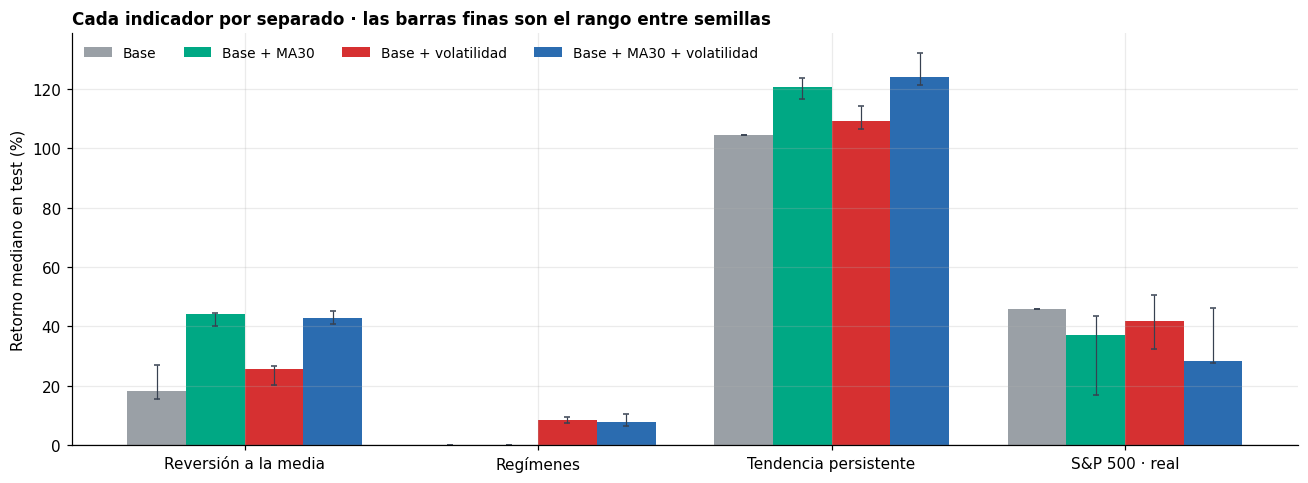

In [21]:
t = pick("indicadores").pivot(index="mercado", columns="estado", values="retorno_mediana")
t = t.reindex(index=MERCADOS_ANEXO, columns=list(COLUMNS)).rename(index=LABELS_ANEXO, columns=STATE_LABELS)
display(t.style.format("{:+.1%}").set_caption("Retorno mediano en test · Q-Learning · mediana entre semillas"))

fig, ax = plt.subplots(figsize=(12, 4.5))
width, colors = .2, ["#9AA0A6", "#00A884", "#D63031", AGENT_COLORS["qlearning"]]
for j, (state, color) in enumerate(zip(COLUMNS, colors)):
    sub = pick("indicadores", estado=state).set_index("mercado").reindex(MERCADOS_ANEXO)
    x = np.arange(len(MERCADOS_ANEXO)) + (j - 1.5) * width
    ax.bar(x, 100 * sub.retorno_mediana, width, color=color, label=STATE_LABELS[state])
    ax.errorbar(x, 100 * sub.retorno_mediana, fmt="none", ecolor="#374151", lw=.8, capsize=2,
                yerr=[100 * (sub.retorno_mediana - sub.minimo_semilla), 100 * (sub.maximo_semilla - sub.retorno_mediana)])
ax.set_xticks(np.arange(len(MERCADOS_ANEXO)), [LABELS_ANEXO[m] for m in MERCADOS_ANEXO])
ax.axhline(0, color="gray", lw=.8); ax.set_ylabel("Retorno mediano en test (%)"); ax.legend(ncol=4, loc="upper left")
ax.set_title("Cada indicador por separado · las barras finas son el rango entre semillas", loc="left")
fig.tight_layout(); figure(fig, "03_anexo_indicadores"); plt.show()

**Lectura.** Cada mercado usa el indicador que su mecanismo predice (§2). En **reversión**, la distancia a MA30 explica toda la mejora: solo con MA30 se obtiene +44,0 %, frente a +42,8 % con ambos y +25,5 % solo con volatilidad. En **regímenes** ocurre lo contrario: la volatilidad sola da +8,5 % y MA30 sola no opera (0 %), porque el régimen bajista se reconoce por su volatilidad y no por la distancia a la media. En **tendencia persistente** aporta sobre todo MA30 (+120,6 % frente a +123,8 % con ambos). En el **S&P 500**, cualquier indicador añadido reduce el retorno frente al base (+45,9 %), y el estado completo es el que más lo reduce. Es decir, en sintéticos basta un indicador bien elegido con 60 estados; añadir el otro no mejora y solo cuesta cobertura.

### 9.2 ¿El estado grande está infraentrenado?

Con 180 estados, cada celda recibe del orden de diez veces menos visitas que con 20 (§6, cobertura). Si el estado enriquecido rinde menos en el S&P 500 por falta de datos, debería mejorar al duplicar o cuadruplicar los episodios. En los sintéticos, la misma prueba dice si 800 episodios ya bastaban. La línea discontinua es el estado base con 800 episodios.

,Base · 800,800 episodios,1600 episodios,3200 episodios,Visitas por celda (×1 → ×4)
mercado,,,,,
Reversión a la media,+18.1%,+42.8%,+42.2%,+42.8%,1745 → 6712
Regímenes,+0.0%,+7.8%,+8.2%,+8.2%,1472 → 4867
Tendencia persistente,+104.5%,+123.8%,+124.5%,+126.0%,810 → 2264
S&P 500 · real,+45.9%,+28.3%,+28.7%,+28.7%,628 → 2360


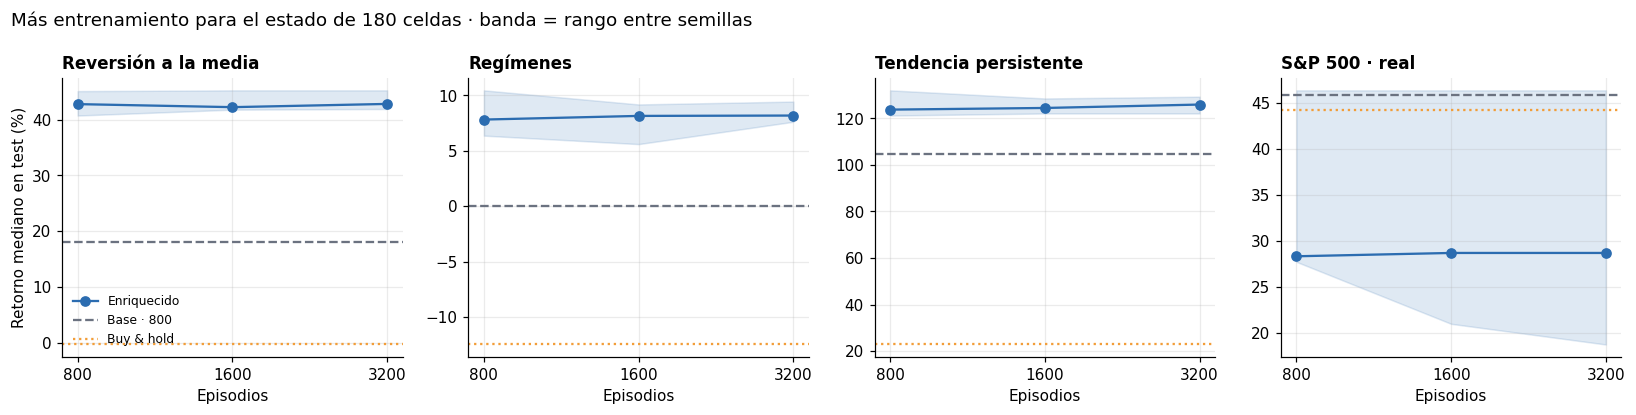

In [22]:
t = pick("presupuesto").pivot(index="mercado", columns="n_episodes", values="retorno_mediana").reindex(MERCADOS_ANEXO)
t.columns = [f"{n} episodios" for n in t.columns]
t.insert(0, f"Base · {N_EP}", pick("indicadores", estado="base").set_index("mercado").retorno_mediana)
visits = pick("presupuesto").pivot(index="mercado", columns="n_episodes", values="visitas_mediana").reindex(MERCADOS_ANEXO)
t["Visitas por celda (×1 → ×4)"] = [f"{a:.0f} → {b:.0f}" for a, b in zip(visits.iloc[:, 0], visits.iloc[:, -1])]
display(t.rename(index=LABELS_ANEXO).style.format("{:+.1%}", subset=t.columns[:-1])
        .set_caption("Estado enriquecido · retorno mediano en test según el número de episodios"))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, m in zip(axes, MERCADOS_ANEXO):
    sub = pick("presupuesto", mercado=m).sort_values("n_episodes")
    ax.plot(sub.n_episodes, 100 * sub.retorno_mediana, "o-", color=AGENT_COLORS["qlearning"], label="Enriquecido")
    ax.fill_between(sub.n_episodes, 100 * sub.minimo_semilla, 100 * sub.maximo_semilla,
                    color=AGENT_COLORS["qlearning"], alpha=.15)
    ax.axhline(100 * pick("indicadores", mercado=m, estado="base").retorno_mediana.iloc[0],
               color="#6B7280", ls="--", label=f"Base · {N_EP}")
    ax.axhline(100 * bh[(m, 0.001, 0)], color=AGENT_COLORS["buy_hold"], ls=":", label="Buy & hold")
    ax.set_xscale("log", base=2); ax.set_xticks(sub.n_episodes, sub.n_episodes)
    ax.set_title(LABELS_ANEXO[m], loc="left"); ax.set_xlabel("Episodios")
axes[0].set_ylabel("Retorno mediano en test (%)"); axes[0].legend(fontsize=8)
fig.suptitle("Más entrenamiento para el estado de 180 celdas · banda = rango entre semillas", x=.01, ha="left")
fig.tight_layout(); figure(fig, "03_anexo_presupuesto"); plt.show()

**Lectura.** Cuadruplicar los episodios multiplica por cuatro las visitas por celda, pero **apenas mueve el resultado**. En el S&P 500 se pasa de +28,3 % a +28,7 % y sigue lejos del base y de buy & hold; en los sintéticos los cambios están dentro del rango entre semillas. Por tanto, la pérdida del estado enriquecido en datos reales no se debe a falta de entrenamiento, al menos hasta 3 200 episodios. Lo más probable es que aprenda patrones de 2017–2021 que no se repiten en 2024–2025, y eso no se arregla entrenando más con el mismo pasado.

### 9.3 Placebos: ¿gana donde no hay nada que ganar?

Dos controles en los que, por construcción, **no hay ventaja aprendible**:

- **Browniano** (mercado 2 del taller): los retornos son independientes, así que ningún indicador del pasado anticipa el siguiente.
- **S&P 500 barajado:** se permutan los retornos diarios dentro de cada split (una permutación por semilla). La distribución de retornos y el precio en cada corte no cambian, de modo que **buy & hold obtiene exactamente el mismo resultado que en la serie real**; solo desaparece el orden temporal, que es lo único que un estado causal puede explotar.

Si los agentes batieran a buy & hold en los placebos tanto como en los datos reales, la ventaja del §7 vendría del azar del recorrido y no de una señal.

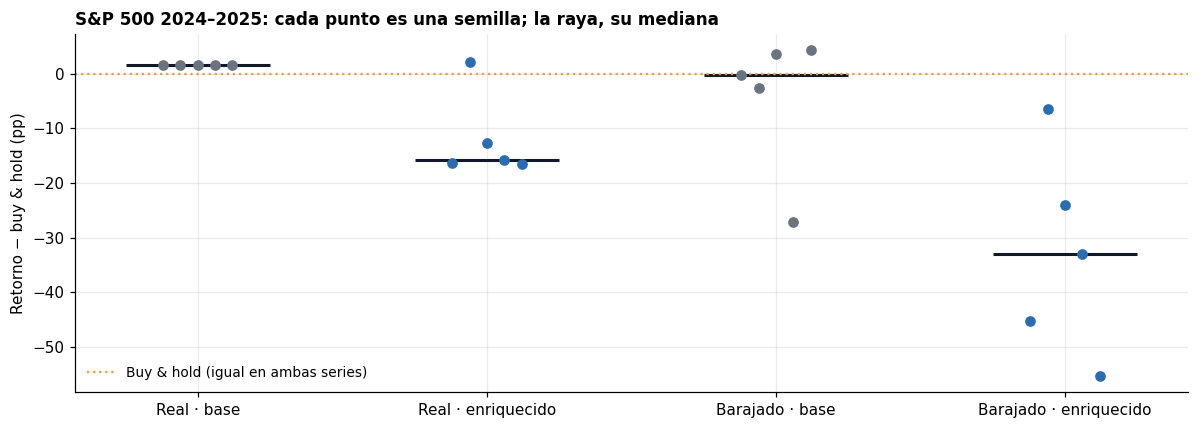

In [23]:
rows = []
for m in ("browniano", "sp500_real", "sp500_barajado"):
    for e in ("base", "enriquecido"):
        sub = pick("indicadores" if m == "sp500_real" else "placebo", mercado=m, estado=e).iloc[0]
        rows.append(dict(mercado=LABELS_ANEXO[m], estado=STATE_LABELS[e], retorno=sub.retorno_mediana,
                         minimo=sub.minimo_semilla, maximo=sub.maximo_semilla, buy_hold=bh[(m, 0.001, 0)],
                         exceso=sub.retorno_mediana - bh[(m, 0.001, 0)], operaciones=sub.n_trades))
placebo = pd.DataFrame(rows).set_index(["mercado", "estado"])
display(placebo.style.format({c: "{:+.1%}" for c in ("retorno", "minimo", "maximo", "buy_hold", "exceso")} | {"operaciones": "{:.0f}"})
        .set_caption("Exceso = retorno del agente − buy & hold (mediana entre semillas)"))

fig, ax = plt.subplots(figsize=(11, 4))
for k, (m, e) in enumerate([(m, e) for m in ("sp500_real", "sp500_barajado") for e in ("base", "enriquecido")]):
    exp_name = "indicadores" if m == "sp500_real" else "placebo"
    seeds = anexo[(anexo.experimento == exp_name) & (anexo.mercado == m) & (anexo.estado == e)]
    excess = 100 * (seeds.retorno_mediana - bh[(m, 0.001, 0)])
    ax.scatter(np.full(len(excess), k) + np.linspace(-.12, .12, len(excess)), excess,
               color=AGENT_COLORS["qlearning"] if e == "enriquecido" else "#6B7280", zorder=3)
    ax.hlines(np.median(excess), k - .25, k + .25, color="#111827", lw=2)
ax.axhline(0, color=AGENT_COLORS["buy_hold"], ls=":", label="Buy & hold (igual en ambas series)")
ax.set_xticks(range(4), ["Real · base", "Real · enriquecido", "Barajado · base", "Barajado · enriquecido"])
ax.set_ylabel("Retorno − buy & hold (pp)"); ax.legend(loc="lower left")
ax.set_title("S&P 500 2024–2025: cada punto es una semilla; la raya, su mediana", loc="left")
fig.tight_layout(); figure(fig, "03_anexo_placebo"); plt.show()

**Lectura.** En el **browniano**, los dos estados aprenden a no operar (0 %), lo correcto cuando no hay señal: el estado grande no se inventa patrones donde no los hay. En el **S&P 500 barajado**, el base vuelve a comprar y mantener (+44,0 %, casi igual que buy & hold), mientras que el enriquecido opera 103 veces y cae a +11,1 %, con semillas entre −11 % y +38 %. Sobre la serie real pierde menos frente a buy & hold (−16 pp en lugar de −33 pp), así que el orden real de los precios le aporta algo, aunque **no lo bastante para batir a buy & hold**. La dispersión del placebo también muestra cuánto puede variar un único recorrido de dos años por puro azar.

### 9.4 ¿Cuánta comisión aguanta cada estrategia?

El entorno cobra un 0,1 % por operación. `CostTradingEnv` copia la contabilidad del taller con la comisión como parámetro (una prueba comprueba que con 0,1 % coincide paso a paso con `SimpleTradingEnv`). El agente **se reentrena con cada comisión**, así que puede adaptarse operando menos. Buy & hold paga una sola compra.

,0.00 %,0.05 %,0.10 %,0.25 %,0.50 %
mercado,,,,,
Reversión a la media,+45.8%,+45.1%,+42.8%,+38.3%,+23.0%
Regímenes,+9.6%,+8.9%,+7.8%,+0.0%,+0.0%
Tendencia persistente,+128.0%,+126.5%,+123.8%,+123.6%,+79.6%


,0.00 %,0.05 %,0.10 %,0.25 %,0.50 %
mercado,,,,,
Reversión a la media,61,45,27,16,6
Regímenes,44,18,12,2,0
Tendencia persistente,30,15,13,8,4


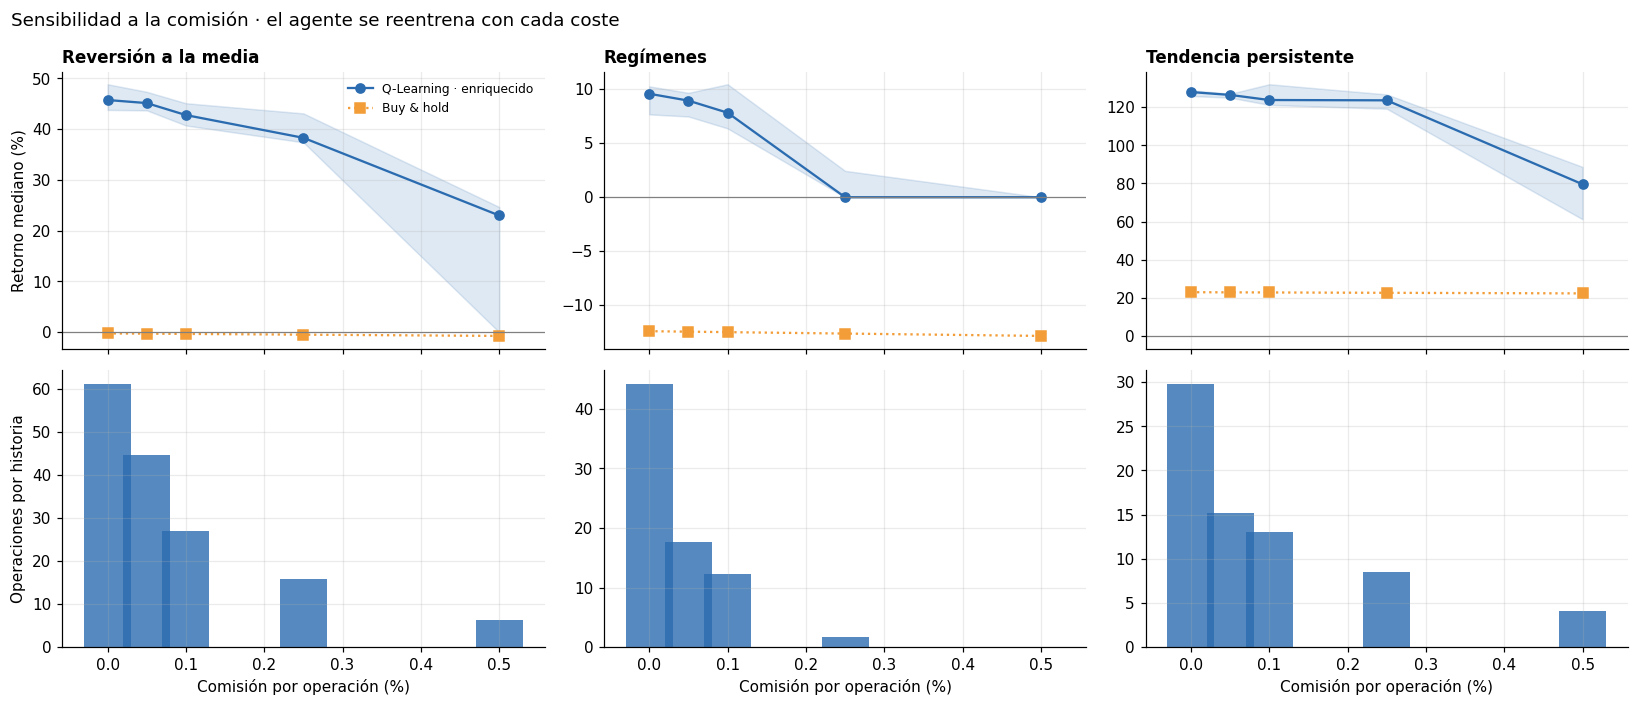

In [24]:
t = pick("comision").pivot(index="mercado", columns="coste", values="retorno_mediana").reindex(MERCADOS_ANEXO[:3])
trades = pick("comision").pivot(index="mercado", columns="coste", values="n_trades").reindex(MERCADOS_ANEXO[:3])
t.columns = trades.columns = [f"{100*c:.2f} %" for c in t.columns]
display(t.rename(index=LABELS_ANEXO).style.format("{:+.1%}").set_caption("Retorno mediano en test según la comisión por operación"))
display(trades.rename(index=LABELS_ANEXO).style.format("{:.0f}").set_caption("Operaciones por historia de test"))

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
for j, m in enumerate(MERCADOS_ANEXO[:3]):
    sub = pick("comision", mercado=m).sort_values("coste")
    x = 100 * sub.coste
    axes[0, j].plot(x, 100 * sub.retorno_mediana, "o-", color=AGENT_COLORS["qlearning"], label="Q-Learning · enriquecido")
    axes[0, j].fill_between(x, 100 * sub.minimo_semilla, 100 * sub.maximo_semilla, color=AGENT_COLORS["qlearning"], alpha=.15)
    axes[0, j].plot(x, [100 * bh[(m, c, 0)] for c in sub.coste], "s:", color=AGENT_COLORS["buy_hold"], label="Buy & hold")
    axes[0, j].axhline(0, color="gray", lw=.8)
    axes[0, j].set_title(LABELS_ANEXO[m], loc="left")
    axes[1, j].bar(x, sub.n_trades, width=.06, color=AGENT_COLORS["qlearning"], alpha=.8)
    axes[1, j].set_xlabel("Comisión por operación (%)")
axes[0, 0].set_ylabel("Retorno mediano (%)"); axes[1, 0].set_ylabel("Operaciones por historia")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Sensibilidad a la comisión · el agente se reentrena con cada coste", x=.01, ha="left")
fig.tight_layout(); figure(fig, "03_anexo_comision"); plt.show()

**Lectura.** El agente **se adapta a la comisión operando menos** (en reversión pasa de 61 operaciones por historia con comisión 0 a 6 con el 0,5 %), y cada mercado aguanta un nivel distinto:
- **Regímenes:** la ventaja es fina y desaparece con el 0,25 %, donde el agente vuelve a no operar. Aun así, no operar sigue batiendo a buy & hold (−12,6 %).
- **Reversión:** la estrategia más robusta. Conserva +23 % con el 0,5 %, aunque una semilla cae a 0 %.
- **Tendencia persistente:** casi no se resiente hasta el 0,25 %, porque opera poco y los movimientos son grandes. Con el 0,5 % baja a +80 %, que sigue muy por encima de buy & hold (+22 %).

La comisión del 0,1 % del taller está en la zona donde las tres estrategias siguen siendo rentables.

### 9.5 ¿Importa el algoritmo TD?

Además de Q-Learning y SARSA se prueban dos variantes del mismo tema (Sutton y Barto, §6.6–6.7), con la misma interfaz y el mismo presupuesto:

- **Expected SARSA:** sustituye $Q(S',A')$ por su valor esperado bajo la política ε-greedy, $\sum_{a'}\pi(a'\mid S')\,Q(S',a')$. Quita el ruido de muestrear $A'$.
- **Double Q-Learning:** dos tablas; una elige $\arg\max_{a'}$ en $S'$ y la otra la valora. Corrige el sesgo optimista de $\max_{a'}Q$ cuando las estimaciones son ruidosas, algo esperable con 180 celdas y ventajas del orden del 0,1 % por paso.

La convergencia es la definición común del proyecto (90 % de la mejora de la media móvil).

algoritmo,Q-Learning,SARSA,Expected SARSA,Double Q-Learning
mercado,,,,
Reversión a la media,+42.8%,+43.8%,+43.9%,+42.3%
Regímenes,+7.8%,+7.5%,+6.5%,+6.6%
Tendencia persistente,+123.8%,+128.7%,+125.9%,+125.4%
S&P 500 · real,+28.3%,+29.9%,+31.8%,+32.5%


algoritmo,Q-Learning,SARSA,Expected SARSA,Double Q-Learning
mercado,,,,
Reversión a la media,247,242,258,246
Regímenes,221,251,245,275
Tendencia persistente,291,291,291,317
S&P 500 · real,315,298,301,293


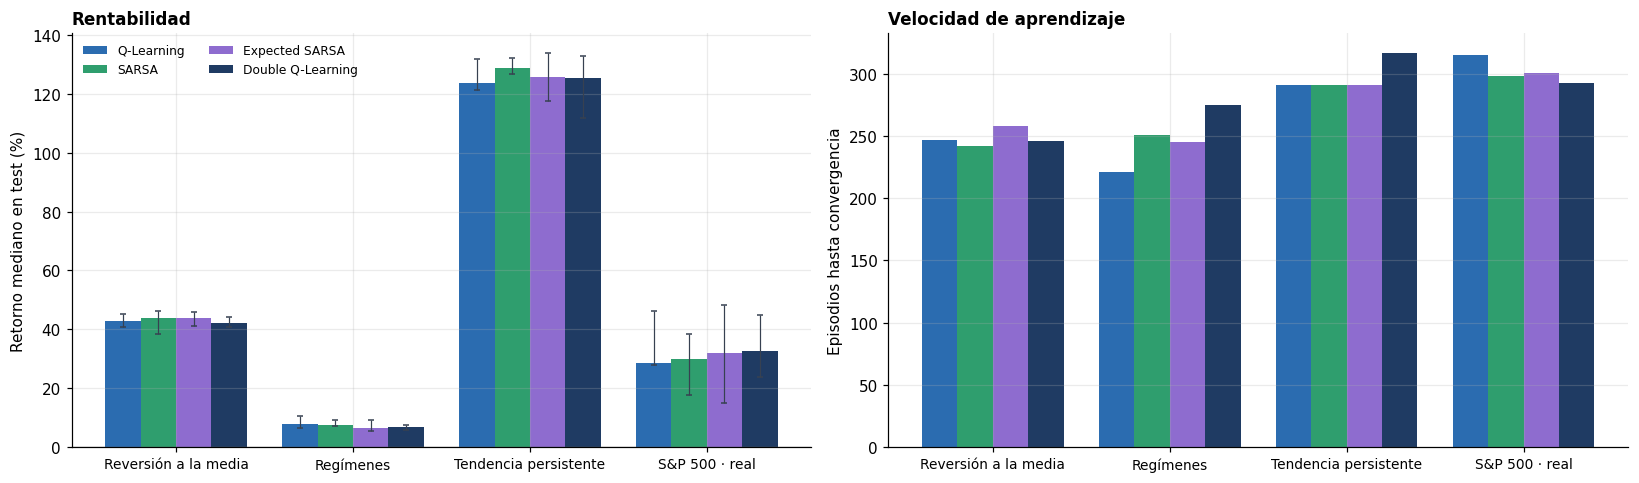

In [25]:
algos = pick("algoritmos")
t = algos.pivot(index="mercado", columns="algoritmo", values="retorno_mediana").reindex(index=MERCADOS_ANEXO, columns=list(ALGORITHMS_ANEXO))
conv = algos.pivot(index="mercado", columns="algoritmo", values="episodios_convergencia").reindex(index=MERCADOS_ANEXO, columns=list(ALGORITHMS_ANEXO))
display(t.rename(index=LABELS_ANEXO, columns=ALGORITHM_LABELS).style.format("{:+.1%}")
        .set_caption("Estado enriquecido · retorno mediano en test por algoritmo"))
display(conv.rename(index=LABELS_ANEXO, columns=ALGORITHM_LABELS).style.format("{:.0f}")
        .set_caption("Episodios hasta la convergencia (mediana entre semillas)"))

algo_colors = {"qlearning": AGENT_COLORS["qlearning"], "sarsa": AGENT_COLORS["sarsa"],
               "expected_sarsa": "#8E6CCF", "double_q": "#1F3B63"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for j, a in enumerate(ALGORITHMS_ANEXO):
    x = np.arange(len(MERCADOS_ANEXO)) + (j - 1.5) * .2
    sub = algos[algos.algoritmo == a].set_index("mercado").reindex(MERCADOS_ANEXO)
    axes[0].bar(x, 100 * sub.retorno_mediana, .2, color=algo_colors[a], label=ALGORITHM_LABELS[a])
    axes[0].errorbar(x, 100 * sub.retorno_mediana, fmt="none", ecolor="#374151", lw=.8, capsize=2,
                     yerr=[100 * (sub.retorno_mediana - sub.minimo_semilla), 100 * (sub.maximo_semilla - sub.retorno_mediana)])
    axes[1].bar(x, sub.episodios_convergencia, .2, color=algo_colors[a])
for ax, ylabel in zip(axes, ("Retorno mediano en test (%)", "Episodios hasta convergencia")):
    ax.set_xticks(np.arange(len(MERCADOS_ANEXO)), [LABELS_ANEXO[m] for m in MERCADOS_ANEXO], fontsize=9)
    ax.set_ylabel(ylabel)
axes[0].axhline(0, color="gray", lw=.8); axes[0].legend(ncol=2, fontsize=8)
axes[0].set_title("Rentabilidad", loc="left"); axes[1].set_title("Velocidad de aprendizaje", loc="left")
fig.tight_layout(); figure(fig, "03_anexo_algoritmos"); plt.show()

**Lectura.** Los cuatro algoritmos acaban casi en el mismo sitio. Las diferencias de retorno (por ejemplo, de +42,3 % a +43,9 % en reversión) quedan dentro del rango entre semillas, y todos convergen entre 220 y 320 episodios. Double Q-Learning no mejora de forma apreciable: con γ=0,9, recompensas de ±1 % y α=0,001, el sesgo del máximo es pequeño frente al ruido. Expected SARSA tampoco destaca, porque ε decae a 0,01 y la política esperada se confunde enseguida con la greedy. Se confirma lo visto en 01–02: **el resultado depende del estado y de los datos, no de la regla TD**.

### 9.6 ¿Importa que la recompensa sume y el capital componga?

La recompensa del taller es el retorno simple del paso menos la comisión, y su suma no es el objetivo real: el balance **compone**. Con $r_t=\log(B_t/B_{t-1})$ la suma del episodio es exactamente $\log(B_T/B_0)$, así que maximizar la recompensa equivale a maximizar el capital final (una prueba lo comprueba). La diferencia debería notarse sobre todo en **tendencia + ciclo**, con un ruido del 10 % por paso, donde sumar y componer se separan más.

recompensa,Recompensa del taller,log(balance),ops. taller,ops. log
mercado,,,,
Tendencia + ciclo,+41092.3%,+43009.3%,60,58
Reversión a la media,+42.8%,+42.8%,27,27
Regímenes,+7.8%,+8.1%,12,10
Tendencia persistente,+123.8%,+126.5%,13,13
S&P 500 · real,+28.3%,+28.7%,79,81


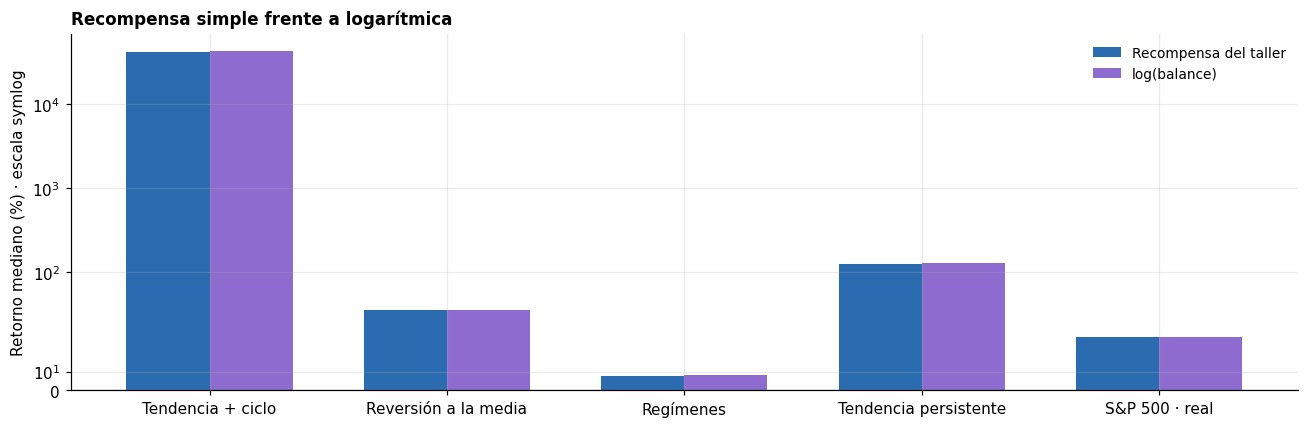

In [26]:
t = pick("recompensa").pivot(index="mercado", columns="recompensa", values="retorno_mediana")
t = t.reindex(index=["tendencia_ciclo", *MERCADOS_ANEXO], columns=["taller", "log"])
trades = pick("recompensa").pivot(index="mercado", columns="recompensa", values="n_trades").reindex(t.index)[["taller", "log"]]
t = t.assign(**{"ops. taller": trades.taller, "ops. log": trades.log})
display(t.rename(index=LABELS_ANEXO, columns={"taller": "Recompensa del taller", "log": "log(balance)"})
        .style.format("{:+.1%}", subset=["Recompensa del taller", "log(balance)"]).format("{:.0f}", subset=["ops. taller", "ops. log"])
        .set_caption("Estado enriquecido · retorno mediano en test según la recompensa"))

fig, ax = plt.subplots(figsize=(12, 4))
markets_r = ["tendencia_ciclo", *MERCADOS_ANEXO]
for j, (r, color) in enumerate((("taller", AGENT_COLORS["qlearning"]), ("log", "#8E6CCF"))):
    sub = pick("recompensa", recompensa=r).set_index("mercado").reindex(markets_r)
    x = np.arange(len(markets_r)) + (j - .5) * .35
    # Escala simétrica logarítmica: tendencia + ciclo multiplica el capital por cientos.
    ax.bar(x, 100 * sub.retorno_mediana, .35, color=color, label="Recompensa del taller" if r == "taller" else "log(balance)")
ax.set_yscale("symlog", linthresh=50)
ax.set_xticks(np.arange(len(markets_r)), [LABELS_ANEXO[m] for m in markets_r])
ax.axhline(0, color="gray", lw=.8); ax.set_ylabel("Retorno mediano (%) · escala symlog"); ax.legend()
ax.set_title("Recompensa simple frente a logarítmica", loc="left")
fig.tight_layout(); figure(fig, "03_anexo_recompensa"); plt.show()

**Lectura.** La recompensa logarítmica no cambia la conclusión en ningún mercado. Hay una leve mejora en **tendencia + ciclo** (×431 frente a ×412, dentro del rango entre semillas, y una caída máxima algo menor: 59 % frente a 63 %) y diferencias de pocos puntos en los demás (como mucho +2,7 pp, en tendencia persistente). Con pasos del 1–2 %, $\log(1+r)\approx r$, así que las dos recompensas ordenan casi igual las acciones. La aproximación del taller es razonable salvo con ruidos muy grandes.

### 9.7 ¿Se repite en otros años reales? Walk-forward anual

El §7 evalúa un único recorrido (2024–2025). Aquí, para cada año de 2019 a 2025, se entrena **solo con los años anteriores** (desde 2017, ventanas de 252 cierres como en el §5) y se evalúa el año completo con la política congelada. Son siete historias reales distintas, con mercados alcistas, la caída de 2020 y el bajista de 2022. Siguen sin ser independientes (comparten el pasado de entrenamiento), pero dicen más que un solo recorrido.

Base: bate a buy & hold en 1 de 7 años; menor caída máxima en 2 de 7
Base + MA30 + volatilidad: bate a buy & hold en 0 de 7 años; menor caída máxima en 4 de 7


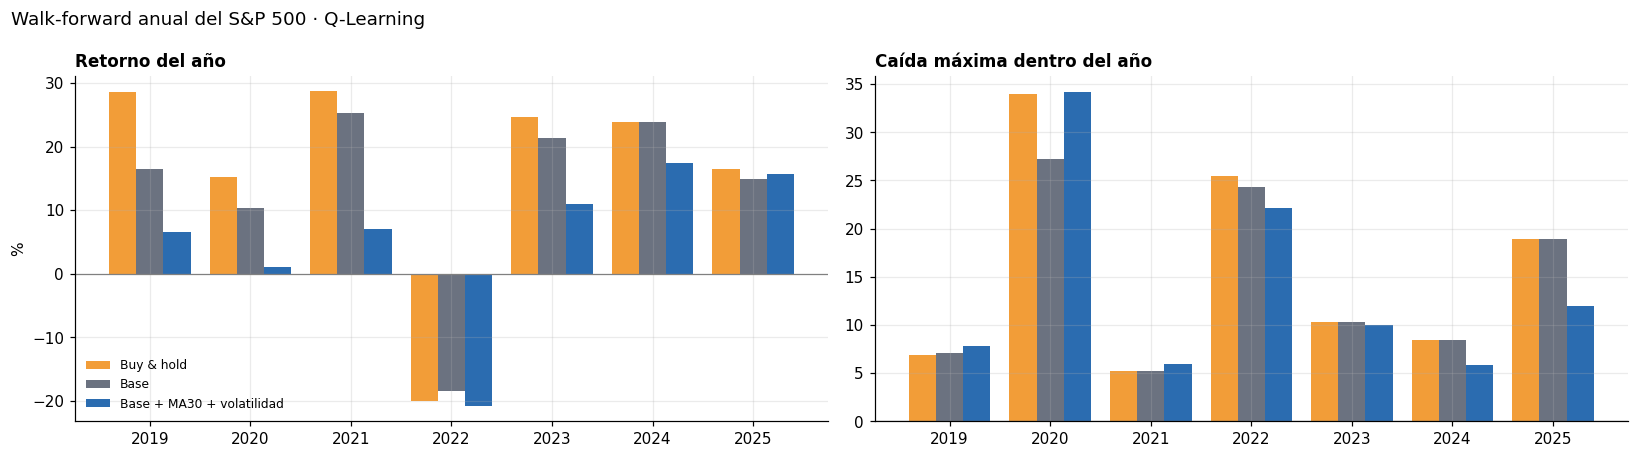

In [27]:
wf = pick("walk_forward").pivot(index="anio", columns="estado", values="retorno_mediana")[["base", "enriquecido"]]
wf_dd = pick("walk_forward").pivot(index="anio", columns="estado", values="max_drawdown")[["base", "enriquecido"]]
wf["buy_hold"] = [bh[("sp500_anual", 0.001, y)] for y in wf.index]
wf_dd["buy_hold"] = [controles.set_index(["agente", "mercado", "coste", "anio"]).max_drawdown[("buy_hold", "sp500_anual", 0.001, y)] for y in wf.index]
table = pd.concat({"Retorno": wf, "Caída máxima": wf_dd}, axis=1)
display(table.style.format("{:+.1%}", subset=["Retorno"]).format("{:.1%}", subset=["Caída máxima"])
        .set_caption("S&P 500 · un año de test cada vez, entrenando con los anteriores · mediana entre semillas"))
for e in ("base", "enriquecido"):
    print(f"{STATE_LABELS[e]}: bate a buy & hold en {int((wf[e] > wf.buy_hold + 1e-9).sum())} de {len(wf)} años; "
          f"menor caída máxima en {int((wf_dd[e] < wf_dd.buy_hold - 1e-9).sum())} de {len(wf)}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
x = np.arange(len(YEARS))
for j, (name, color) in enumerate((("buy_hold", AGENT_COLORS["buy_hold"]), ("base", "#6B7280"), ("enriquecido", AGENT_COLORS["qlearning"]))):
    label = "Buy & hold" if name == "buy_hold" else STATE_LABELS[name]
    axes[0].bar(x + (j - 1) * .27, 100 * wf[name], .27, color=color, label=label)
    axes[1].bar(x + (j - 1) * .27, 100 * wf_dd[name], .27, color=color)
for ax, title in zip(axes, ("Retorno del año", "Caída máxima dentro del año")):
    ax.set_xticks(x, YEARS); ax.set_title(title, loc="left"); ax.axhline(0, color="gray", lw=.8)
axes[0].set_ylabel("%"); axes[0].legend(fontsize=8)
fig.suptitle("Walk-forward anual del S&P 500 · Q-Learning", x=.01, ha="left")
fig.tight_layout(); figure(fig, "03_anexo_walk_forward"); plt.show()

**Lectura.** En siete años de test, **ningún agente bate de forma consistente a buy & hold**. El base casi siempre acaba comprando y manteniendo: una operación desde 2021, con un resultado igual a buy & hold en 2024 y ligeramente mejor en 2022 (−18,4 % frente a −20,0 %). El enriquecido opera de 27 a 66 veces al año y queda por debajo de buy & hold los siete años, aunque reduce la caída máxima en algunos, como 2025 (12 % frente a 19 %) o 2024 (6 % frente a 8 %). En la caída de 2020 no protege: su caída máxima es igual o mayor. Coincide con el §7: en el índice real, los indicadores técnicos simples cambian rentabilidad por menor caída máxima, pero no generan ventaja.

### 9.8 ¿Qué ha aprendido el estado enriquecido?

Se dibuja la política greedy (semilla 0, fijada de antemano) como **exposición deseada** en cada celda: verde = entra y se queda, amarillo = mantiene si ya está dentro pero no entra (la histéresis que crea la comisión), rojo = fuera, gris = celda no visitada en train. Filas: bin de la tendencia corta (0 = caída más fuerte). Columnas: distancia a MA30 (por debajo, cerca, por encima). Un panel por tercil de volatilidad.

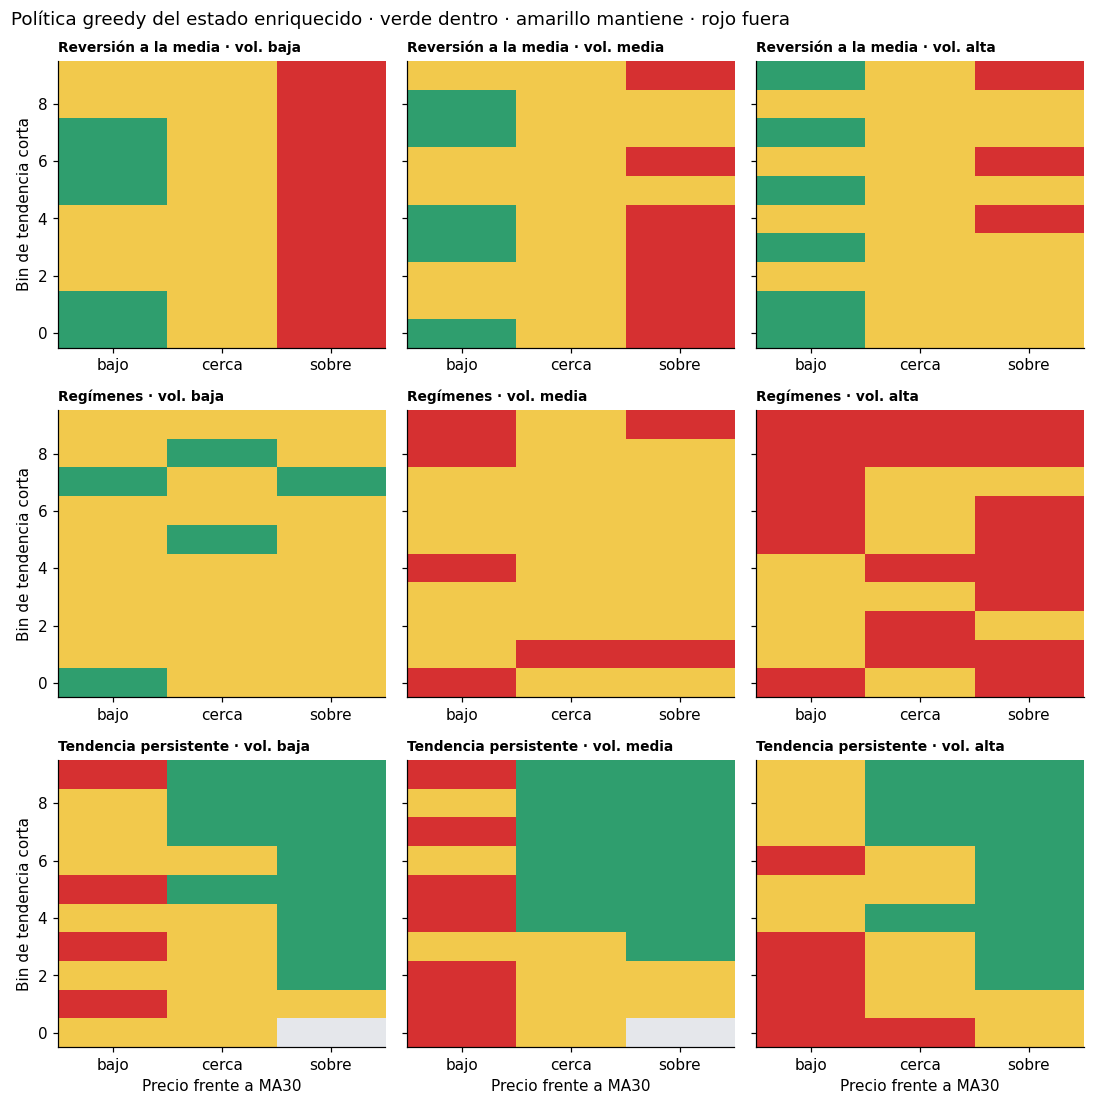

In [28]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#D63031", "#F2C94C", "#2F9E6E"]); cmap.set_bad("#E5E7EB")
map_markets = ["reversion_media", "regimenes", "tendencia_persistente"]
fig, axes = plt.subplots(len(map_markets), 3, figsize=(10, 3.4 * len(map_markets)), sharey=True)
for i, m in enumerate(map_markets):
    exposure = exposure_map(dict(ANEXO, mercado=m, seed=SEEDS[0]))  # (tendencia, MA30, volatilidad)
    for v, ax in enumerate(axes[i]):
        ax.imshow(exposure[:, :, v], cmap=cmap, vmin=0, vmax=1, aspect="auto", origin="lower")
        ax.set_xticks(range(exposure.shape[1]), ["bajo", "cerca", "sobre"][:exposure.shape[1]])
        ax.set_title(f"{LABELS_ANEXO[m]} · vol. {['baja', 'media', 'alta'][v]}", loc="left", fontsize=9)
        ax.grid(False)
    axes[i, 0].set_ylabel("Bin de tendencia corta")
for ax in axes[-1]:
    ax.set_xlabel("Precio frente a MA30")
fig.suptitle("Política greedy del estado enriquecido · verde dentro · amarillo mantiene · rojo fuera", x=.01, ha="left")
fig.tight_layout(); figure(fig, "03_anexo_politica"); plt.show()

**Lectura.** La tabla Q enriquecida recupera **reglas con sentido económico** sin que se le hayan programado:
- **Reversión:** entra cuando el precio está por debajo de MA30 y sale cuando está por encima: compra barato y vende caro respecto al equilibrio.
- **Regímenes:** con volatilidad baja está dentro o mantiene, y con volatilidad alta casi siempre está fuera. Es su forma de detectar el régimen bajista.
- **Tendencia persistente:** está dentro cuando el precio supera la MA30, como un seguidor de tendencia clásico.

Las zonas amarillas son la histéresis que crea la comisión: si ya está dentro mantiene, pero no entra. Las pocas celdas grises, sin visitas, aparecen en las combinaciones más raras.

### 9.9 Conclusiones del anexo

Se generan a partir de los resultados anteriores y se guardan en `results/03_anexo_conclusiones.md`, junto a `03_anexo.csv` (mediana entre semillas), `03_anexo_semillas.csv` (una fila por entrenamiento y experimento) y `03_anexo_controles.csv` (buy & hold y no operar con las mismas historias y comisión).

In [29]:
ind = pick("indicadores").set_index(["mercado", "estado"]).retorno_mediana
pres = pick("presupuesto").set_index(["mercado", "n_episodes"]).retorno_mediana
alg = pick("algoritmos").set_index(["mercado", "algoritmo"]).retorno_mediana
com = pick("comision").set_index(["mercado", "coste"])
rec = pick("recompensa").set_index(["mercado", "recompensa"]).retorno_mediana
best_single = {m: max(("ma30", "vol"), key=lambda e: ind[(m, e)]) for m in MERCADOS_ANEXO}
lines = ["# 03 · Anexo: pruebas de robustez", "",
         f"Ejecución {'rápida de comprobación' if QUICK else 'completa'}: {len(SEEDS)} semillas, {N_EP} episodios de referencia, "
         f"{N_TEST} historias sintéticas de test; {anexo.id.nunique()} entrenamientos. Q-Learning y estado enriquecido salvo "
         "el factor estudiado; configuraciones fijadas antes del test.", "",
         "## Qué indicador aporta", ""]
for m in MERCADOS_ANEXO:
    lines.append(f"- **{LABELS_ANEXO[m]}:** base {ind[(m, 'base')]:+.1%} · +MA30 {ind[(m, 'ma30')]:+.1%} · "
                 f"+volatilidad {ind[(m, 'vol')]:+.1%} · ambos {ind[(m, 'enriquecido')]:+.1%}. "
                 f"Mejor indicador por separado: {'MA30' if best_single[m] == 'ma30' else 'volatilidad'}.")
lines += ["", "## Presupuesto, placebos, comisión, algoritmo y recompensa", ""]
lines.append("- **Presupuesto:** con ×4 episodios el enriquecido pasa de "
             + ", ".join(f"{LABELS_ANEXO[m]} {pres[(m, N_EP)]:+.1%} → {pres[(m, 4*N_EP)]:+.1%}" for m in MERCADOS_ANEXO)
             + ". Más entrenamiento no cierra la distancia en el S&P 500.")
pb = placebo.retorno
lines.append(f"- **Placebos:** browniano base {pb[('Browniano', 'Base')]:+.1%} y enriquecido {pb[('Browniano', STATE_LABELS['enriquecido'])]:+.1%}; "
             f"S&P 500 barajado base {pb[('S&P 500 · barajado', 'Base')]:+.1%} y enriquecido {pb[('S&P 500 · barajado', STATE_LABELS['enriquecido'])]:+.1%}, "
             f"con buy & hold {bh[('sp500_barajado', 0.001, 0)]:+.1%} en ambas series.")
for m in MERCADOS_ANEXO[:3]:
    lines.append(f"- **Comisión · {LABELS_ANEXO[m]}:** " + " · ".join(
        f"{100*c:.2f} % → {com.loc[(m, c), 'retorno_mediana']:+.1%} ({com.loc[(m, c), 'n_trades']:.0f} ops.)" for c in COSTES)
        + f"; buy & hold {bh[(m, 0.001, 0)]:+.1%}.")
lines.append("- **Algoritmo:** rango entre algoritmos de " + ", ".join(
    f"{LABELS_ANEXO[m]} [{min(alg[(m, a)] for a in ALGORITHMS_ANEXO):+.1%}, {max(alg[(m, a)] for a in ALGORITHMS_ANEXO):+.1%}]"
    for m in MERCADOS_ANEXO) + ".")
lines.append("- **Recompensa log:** " + ", ".join(
    f"{LABELS_ANEXO[m]} {rec[(m, 'taller')]:+.1%} → {rec[(m, 'log')]:+.1%}" for m in ["tendencia_ciclo", *MERCADOS_ANEXO]) + ".")
lines += ["", "## Walk-forward anual del S&P 500", ""]
for y in wf.index:
    lines.append(f"- **{y}:** buy & hold {wf.loc[y, 'buy_hold']:+.1%} · base {wf.loc[y, 'base']:+.1%} · "
                 f"enriquecido {wf.loc[y, 'enriquecido']:+.1%} (caída máxima {wf_dd.loc[y, 'buy_hold']:.1%} · "
                 f"{wf_dd.loc[y, 'base']:.1%} · {wf_dd.loc[y, 'enriquecido']:.1%}).")
lines += ["", "## Lectura conjunta", "",
          "- La mejora del estado enriquecido en sintéticos procede de **un indicador por mercado**, el que su mecanismo predice: "
          "distancia a MA30 en reversión y tendencia, volatilidad en regímenes.",
          "- El estado de 180 celdas no está limitado por el entrenamiento, y el resultado apenas depende del algoritmo TD o de la forma de la recompensa: "
          "**lo que decide es qué información recibe el agente**.",
          "- Los placebos se comportan como deben: sin señal, el agente no opera o se limita a comprar y mantener.",
          "- En el S&P 500 ningún estado bate de forma consistente a buy & hold en siete años de test. Los indicadores reducen a veces la caída máxima, "
          "a costa de rentabilidad.",
          "- Las comparaciones no corrigen por pruebas múltiples, y las historias reales siguen sin ser independientes entre sí."]
(RESULTS_DIR / f"03_anexo_conclusiones{SUF}.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
display(Markdown("\n".join(lines)))
assert len(resumen) == resumen[GROUP].drop_duplicates().shape[0] and np.isfinite(resumen.retorno_mediana).all()
print("OK: resumen, controles, conclusiones y figuras del anexo guardados.")

# 03 · Anexo: pruebas de robustez

Ejecución completa: 5 semillas, 800 episodios de referencia, 200 historias sintéticas de test; 360 entrenamientos. Q-Learning y estado enriquecido salvo el factor estudiado; configuraciones fijadas antes del test.

## Qué indicador aporta

- **Reversión a la media:** base +18.1% · +MA30 +44.0% · +volatilidad +25.5% · ambos +42.8%. Mejor indicador por separado: MA30.
- **Regímenes:** base +0.0% · +MA30 +0.0% · +volatilidad +8.5% · ambos +7.8%. Mejor indicador por separado: volatilidad.
- **Tendencia persistente:** base +104.5% · +MA30 +120.6% · +volatilidad +109.0% · ambos +123.8%. Mejor indicador por separado: MA30.
- **S&P 500 · real:** base +45.9% · +MA30 +37.2% · +volatilidad +41.8% · ambos +28.3%. Mejor indicador por separado: volatilidad.

## Presupuesto, placebos, comisión, algoritmo y recompensa

- **Presupuesto:** con ×4 episodios el enriquecido pasa de Reversión a la media +42.8% → +42.8%, Regímenes +7.8% → +8.2%, Tendencia persistente +123.8% → +126.0%, S&P 500 · real +28.3% → +28.7%. Más entrenamiento no cierra la distancia en el S&P 500.
- **Placebos:** browniano base +0.0% y enriquecido +0.0%; S&P 500 barajado base +44.0% y enriquecido +11.1%, con buy & hold +44.2% en ambas series.
- **Comisión · Reversión a la media:** 0.00 % → +45.8% (61 ops.) · 0.05 % → +45.1% (45 ops.) · 0.10 % → +42.8% (27 ops.) · 0.25 % → +38.3% (16 ops.) · 0.50 % → +23.0% (6 ops.); buy & hold -0.3%.
- **Comisión · Regímenes:** 0.00 % → +9.6% (44 ops.) · 0.05 % → +8.9% (18 ops.) · 0.10 % → +7.8% (12 ops.) · 0.25 % → +0.0% (2 ops.) · 0.50 % → +0.0% (0 ops.); buy & hold -12.5%.
- **Comisión · Tendencia persistente:** 0.00 % → +128.0% (30 ops.) · 0.05 % → +126.5% (15 ops.) · 0.10 % → +123.8% (13 ops.) · 0.25 % → +123.6% (8 ops.) · 0.50 % → +79.6% (4 ops.); buy & hold +22.8%.
- **Algoritmo:** rango entre algoritmos de Reversión a la media [+42.3%, +43.9%], Regímenes [+6.5%, +7.8%], Tendencia persistente [+123.8%, +128.7%], S&P 500 · real [+28.3%, +32.5%].
- **Recompensa log:** Tendencia + ciclo +41092.3% → +43009.3%, Reversión a la media +42.8% → +42.8%, Regímenes +7.8% → +8.1%, Tendencia persistente +123.8% → +126.5%, S&P 500 · real +28.3% → +28.7%.

## Walk-forward anual del S&P 500

- **2019:** buy & hold +28.6% · base +16.5% · enriquecido +6.6% (caída máxima 6.8% · 7.1% · 7.9%).
- **2020:** buy & hold +15.2% · base +10.4% · enriquecido +1.0% (caída máxima 33.9% · 27.2% · 34.2%).
- **2021:** buy & hold +28.7% · base +25.3% · enriquecido +7.0% (caída máxima 5.2% · 5.2% · 5.9%).
- **2022:** buy & hold -20.0% · base -18.4% · enriquecido -20.7% (caída máxima 25.5% · 24.3% · 22.2%).
- **2023:** buy & hold +24.6% · base +21.3% · enriquecido +11.0% (caída máxima 10.3% · 10.3% · 10.0%).
- **2024:** buy & hold +23.9% · base +23.9% · enriquecido +17.4% (caída máxima 8.5% · 8.5% · 5.8%).
- **2025:** buy & hold +16.5% · base +14.9% · enriquecido +15.8% (caída máxima 18.9% · 18.9% · 12.0%).

## Lectura conjunta

- La mejora del estado enriquecido en sintéticos procede de **un indicador por mercado**, el que su mecanismo predice: distancia a MA30 en reversión y tendencia, volatilidad en regímenes.
- El estado de 180 celdas no está limitado por el entrenamiento, y el resultado apenas depende del algoritmo TD o de la forma de la recompensa: **lo que decide es qué información recibe el agente**.
- Los placebos se comportan como deben: sin señal, el agente no opera o se limita a comprar y mantener.
- En el S&P 500 ningún estado bate de forma consistente a buy & hold en siete años de test. Los indicadores reducen a veces la caída máxima, a costa de rentabilidad.
- Las comparaciones no corrigen por pruebas múltiples, y las historias reales siguen sin ser independientes entre sí.

OK: resumen, controles, conclusiones y figuras del anexo guardados.
